# Rice Leaf Disease Detection Using Convolutional Neural Network (CNN)

## Project Introduction

Rice is one of the most important food crops in the world and plays a significant role in global food security. However, rice production is affected by various plant diseases that can reduce crop quality and yield.
Early and accurate identification of rice leaf disease is important for effective crop management. Traditional disease identification mainly depends on visual inspection by farmer or agriculture experts, which can be time-consuming and may require specialized knowledge.
With the development of Artificial Intelligence and Deep Learning, image-based disease detection has become a promising approach for identifying plant disease automatically.
In this project, we will develop an image classification system using  Convolutional Neural Network (CNN) to identify three rice leaf diseases from leaf image:

-Bacterial Leaf Blight
-Brown Spot
-Leaf Smut

The project will also investigate the impact of data augmentation and compare different deep learning approaches to identify a suitable model for rice leaf disease classification.

## Project objectives

1.Understand and analyze the rice leaf image dataset.
2.Perform Exploratory data Analysis (EDA) on the image dataset.
3.Preprocess image for deep learning.
4.Develop a CNN-based image classification model.
5.Apply data augmentation and analyze its impact on model performance.
6.Compare different models using appropriate evaluation metrics.
7.Identify the most suitable model for the classification task.
8.Discuss challenges, solutions, and possible real-world application.

**Note on running this notebook:**
- The dataset (PRCP-1001-RiceLeaf) can be downloaded from the link given in the project problem statement. After extracting it, place the folder named `Data` in the same folder as this notebook.
- The outputs saved in this notebook come from one complete run. Models trained without augmentation give the same results on every run. Models trained with data augmentation can differ slightly between runs because the augmentation is random, so their cross-validation accuracy may change by a few percentage points. The conclusions remain the same.
- Running the whole notebook takes several minutes because of the two cross-validation sections.

## Importing Required Libraries

In [1]:
# Importing required Libraries

import os
import pandas as pd 
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image 

import tensorflow as tf
from tensorflow import keras 
from tensorflow.keras import layers
# Set random seed for reproducibility

tf.keras.utils.set_random_seed(42)

tf.config.experimental.enable_op_determinism()

from sklearn.model_selection import train_test_split
from sklearn.metrics import(
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# Task 1: Data Analysis Report

**Task:** Prepare a complete data analysis report on the given data.

The following sections explore the rice leaf disease dataset: its structure, class distribution, image sizes, image quality, duplicates, and color and brightness patterns, followed by an EDA summary and conclusion.

## Data Loading & Understanding

In [2]:
# Define dataset Path
DATASET_PATH = "Data"

# Check whether the dataset folder exists
if os.path.exists(DATASET_PATH):
    print("Dataset folder found successfully!")
else:
    print("Dataset folder not found. please check the path.")
print("\nDataset Path:",os.path.abspath(DATASET_PATH))
    

Dataset folder found successfully!

Dataset Path: C:\Users\admin\DataScience_Internship_Projects\Rice_Leaf_Disease_CNN_claude\Data


In [3]:
# Display folders inside the data dictionary

print("Folders inside Data:\n")

for folder in os.listdir(DATASET_PATH):
    folder_path = os.path.join(DATASET_PATH,folder)

    if os.path.isdir(folder_path):
        print("Main Folder:",folder)

        for subfolder in os.listdir(folder_path):
            subfolder_path = os.path.join(folder_path,subfolder)

            if os.path.isdir(subfolder_path):
                print(" subfolder:",subfolder)

                for inner_folder in os.listdir(subfolder_path):
                    inner_path = os.path.join(subfolder_path,inner_folder)

                    if os.path.isdir(inner_path):
                        print(" Inner Folder:",inner_folder)


Folders inside Data:

Main Folder: Bacterial leaf blight-20200814T055237Z-001
 subfolder: Bacterial leaf blight
Main Folder: Brown spot-20200814T055208Z-001
 subfolder: Brown spot
Main Folder: Leaf smut-20200814T055530Z-001
 subfolder: Leaf smut


In [4]:

# Explore the folder structure recursively

for root, dirs, files in os.walk(DATASET_PATH):

    level = root.replace(DATASET_PATH, "").count(os.sep)

    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    sub_indent = " " * 4 * (level + 1)

    for file in files[:5]:
        print(f"{sub_indent}{file}")


Data/
    Bacterial leaf blight-20200814T055237Z-001.zip
    Brown spot-20200814T055208Z-001.zip
    Leaf smut-20200814T055530Z-001.zip
    Bacterial leaf blight-20200814T055237Z-001/
        Bacterial leaf blight/
            DSC_0365.JPG
            DSC_0366.jpg
            DSC_0367.JPG
            DSC_0370.jpg
            DSC_0372.JPG
    Brown spot-20200814T055208Z-001/
        Brown spot/
            DSC_0100.jpg
            DSC_0101.jpg
            DSC_0104.jpg
            DSC_0105.jpg
            DSC_0106.jpg
    Leaf smut-20200814T055530Z-001/
        Leaf smut/
            DSC_0293.JPG
            DSC_0308.JPG
            DSC_0309.JPG
            DSC_0310.JPG
            DSC_0312.JPG


In [5]:
# Define actual disease image folders

disease_folders = {
    "Bacterial Leaf Blight":os.path.join(
        DATASET_PATH,
        "Bacterial leaf blight-20200814T055237Z-001",
        "Bacterial leaf blight"
    ),
     "Brown Spot": os.path.join(
        DATASET_PATH,
        "Brown spot-20200814T055208Z-001",
        "Brown spot"
    ),

    "Leaf Smut": os.path.join(
        DATASET_PATH,
        "Leaf smut-20200814T055530Z-001",
        "Leaf smut"
    )
    
}
# Count images in each disease folder

image_counts = {}

valid_extensions = (".jpg", ".jpeg", ".png")

for disease, folder_path in disease_folders.items():

    images = [
        file for file in os.listdir(folder_path)
        if file.lower().endswith(valid_extensions)
    ]

    image_counts[disease] = len(images)

    print(f"{disease}: {len(images)} images")

# Calculate total images

total_images = sum(image_counts.values())

print("\nTotal Number of Images:", total_images)


Bacterial Leaf Blight: 40 images
Brown Spot: 40 images
Leaf Smut: 39 images

Total Number of Images: 119


In [6]:
# create a list to store image information

image_data=[]

for disease, folder_path in disease_folders.items():
    
    for file in os.listdir(folder_path):
        
        if file.lower().endswith((".jpg",".jpeg",".png")):

            image_path = os.path.join(folder_path, file)

            image_data.append({
                "Image_Name":file,
                "Disease":disease,
                "Image_Path":image_path
            })

# convert list into dataframe
    
crops = pd.DataFrame(image_data)

 #Display first 5 records

crops.head()

,Image_Name,Disease,Image_Path
0,DSC_0365.JPG,Bacterial Leaf Blight,Data\Bacterial leaf blight-20200814T055237Z-00...
1,DSC_0366.jpg,Bacterial Leaf Blight,Data\Bacterial leaf blight-20200814T055237Z-00...
2,DSC_0367.JPG,Bacterial Leaf Blight,Data\Bacterial leaf blight-20200814T055237Z-00...
3,DSC_0370.jpg,Bacterial Leaf Blight,Data\Bacterial leaf blight-20200814T055237Z-00...
4,DSC_0372.JPG,Bacterial Leaf Blight,Data\Bacterial leaf blight-20200814T055237Z-00...


In [7]:
crops

,Image_Name,Disease,Image_Path
0,DSC_0365.JPG,Bacterial Leaf Blight,Data\Bacterial leaf blight-20200814T055237Z-00...
1,DSC_0366.jpg,Bacterial Leaf Blight,Data\Bacterial leaf blight-20200814T055237Z-00...
2,DSC_0367.JPG,Bacterial Leaf Blight,Data\Bacterial leaf blight-20200814T055237Z-00...
3,DSC_0370.jpg,Bacterial Leaf Blight,Data\Bacterial leaf blight-20200814T055237Z-00...
4,DSC_0372.JPG,Bacterial Leaf Blight,Data\Bacterial leaf blight-20200814T055237Z-00...
...,...,...,...
114,DSC_0512.jpg,Leaf Smut,Data\Leaf smut-20200814T055530Z-001\Leaf smut\...
115,DSC_0513.jpg,Leaf Smut,Data\Leaf smut-20200814T055530Z-001\Leaf smut\...
116,DSC_0514.jpg,Leaf Smut,Data\Leaf smut-20200814T055530Z-001\Leaf smut\...
117,DSC_0515.jpg,Leaf Smut,Data\Leaf smut-20200814T055530Z-001\Leaf smut\...


In [8]:
# Check dataset shape

print("Dataset Shape:", crops.shape)

# Check column information

print("\nDataset Information:")
crops.info()

# Check missing values

print("\nMissing Values:")
print(crops.isnull().sum())

#check duplicate records
print("\nDuplicate Records:")
print(" Number of Duplicate Rows:",crops.duplicated().sum())

Dataset Shape: (119, 3)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Image_Name  119 non-null    object
 1   Disease     119 non-null    object
 2   Image_Path  119 non-null    object
dtypes: object(3)
memory usage: 2.9+ KB

Missing Values:
Image_Name    0
Disease       0
Image_Path    0
dtype: int64

Duplicate Records:
 Number of Duplicate Rows: 0


## Exploratory Data Analysis (EDA)

Disease Class Distribution:

Disease
Bacterial Leaf Blight    40
Brown Spot               40
Leaf Smut                39
Name: count, dtype: int64


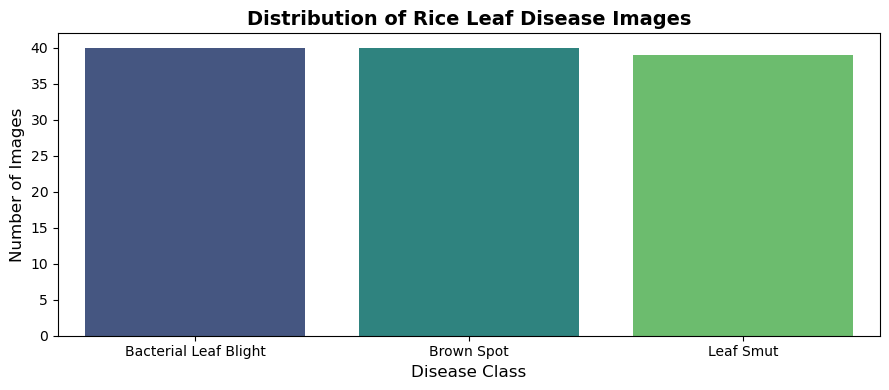

In [9]:
# count images in each disease class

class_counts = crops["Disease"].value_counts()

print("Disease Class Distribution:\n")
print(class_counts)

# plot disease class distribution 

plt.figure(figsize=(9,4))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    hue=class_counts.index,
    palette="viridis",
    legend=False
)

plt.title("Distribution of Rice Leaf Disease Images",fontsize=14,fontweight="bold")
plt.xlabel("Disease Class",fontsize=12)
plt.ylabel("Number of Images",fontsize=12)

plt.tight_layout()
plt.show()

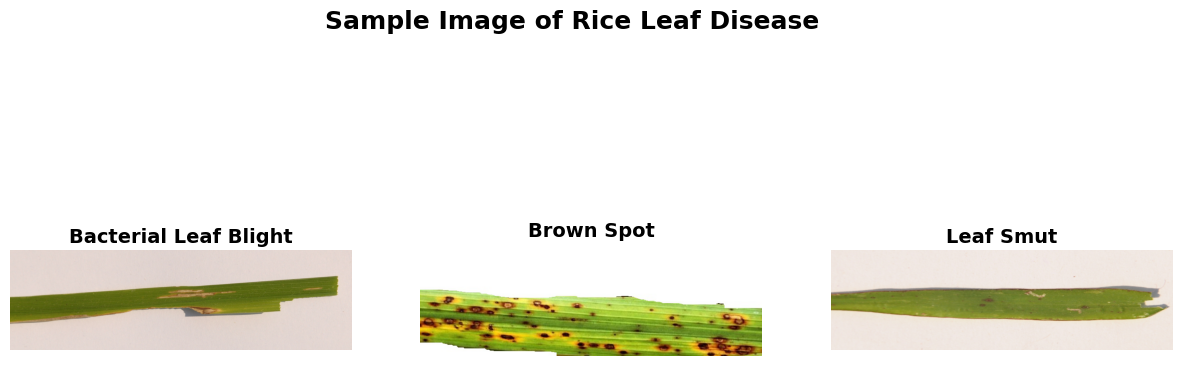

In [10]:
# Display sample images from each disease class

plt.figure(figsize=(15,6))

for i, disease in enumerate(crops["Disease"].unique()):
    sample = crops[crops["Disease"] == disease].iloc[0]
    image = Image.open(sample["Image_Path"])

    plt.subplot(1, 3, i + 1)
    plt.imshow(image)
    plt.title(disease, fontsize=14, fontweight="bold")
    plt.axis("off")

plt.suptitle("Sample Image of Rice Leaf Disease",fontsize=18,fontweight="bold")  
plt.show()

In [11]:
# Analyze image properties

image_properties = []
for _, row in crops.iterrows():

    image = Image.open(row["Image_Path"])

    image_properties.append({
        "Image_Name": row["Image_Name"],
        "Disease":row["Disease"],
        "Image_Path": row["Image_Path"],
        "Width":image.width,
        "Height":image.height,
        "Mode":image.mode,
        "Format":image.format
    })

#create dataframe
image_info = pd.DataFrame(image_properties)

#diaplay first 5 records
image_info.head()

,Image_Name,Disease,Image_Path,Width,Height,Mode,Format
0,DSC_0365.JPG,Bacterial Leaf Blight,Data\Bacterial leaf blight-20200814T055237Z-00...,3081,897,RGB,JPEG
1,DSC_0366.jpg,Bacterial Leaf Blight,Data\Bacterial leaf blight-20200814T055237Z-00...,3081,897,RGB,JPEG
2,DSC_0367.JPG,Bacterial Leaf Blight,Data\Bacterial leaf blight-20200814T055237Z-00...,3081,897,RGB,JPEG
3,DSC_0370.jpg,Bacterial Leaf Blight,Data\Bacterial leaf blight-20200814T055237Z-00...,3081,897,RGB,JPEG
4,DSC_0372.JPG,Bacterial Leaf Blight,Data\Bacterial leaf blight-20200814T055237Z-00...,3081,897,RGB,JPEG


In [12]:
# check image dimention

print("Image Dimention Summary:\n")
print("Unique Widths:",image_info["Width"].unique())
print("\nUnique Heigth:",image_info["Height"].unique())
print("\nNumber of unique Dimenssions:",
     image_info[["Width","Height"]].drop_duplicates().shape[0])
print("----------------------------------------------------------------------")

# Display dimension frequency
print("\nImage Dimension:")
dimension_frequency = (image_info.groupby(["Width","Height"])
    .size()
.reset_index(name="Image_Count")
)
print(dimension_frequency)

Image Dimention Summary:

Unique Widths: [3081  766  617 1530 1480 1504  765  763  699  456  316  427  768  296
  286  340  467  359  311 1200  376  367  301  614  250  946  948  537
  503  510  565  562  741]

Unique Heigth: [897 250 244 371 279 323 224 268 197 124 127 193 514  88  92  94 104 168
 170 900  80  73  71 409 200 255 233 211 216 174 383 217 291]

Number of unique Dimenssions: 34
----------------------------------------------------------------------

Image Dimension:
    Width  Height  Image_Count
0     250     200            2
1     286      92            1
2     296      88            1
3     301      71            1
4     311     170            1
5     316     127            1
6     340      94            1
7     359     168            1
8     367      73            1
9     376      80            1
10    427     193            1
11    456     124            1
12    467     104            1
13    503     174            1
14    510     383            1
15    537     216   


**Observation:**

- The dataset contains images with different widths and heights.
- A total of 34 unique image dimensions were identified.
- Therefore, all images need to be resized to a fixed dimension before feeding them into the CNN model.


In [13]:
# Analyze image color modes
print("Image Color Mode Distribution:\n")
mode_counts = image_info["Mode"].value_counts()
print(mode_counts)

Image Color Mode Distribution:

Mode
RGB    119
Name: count, dtype: int64



**Observation:**

- All 119 images are in RGB color mode.
- No grayscale images were found in the dataset.
- Therefore, all images contain three color channels (Red, Green, Blue).


In [14]:
# Analyze image format
print("Image File Format Distribution:\n")
formate_counts = image_info["Format"].value_counts()
print(formate_counts)

Image File Format Distribution:

Format
JPEG    119
Name: count, dtype: int64



**Observation:**

- All 119 images are in JPEG format.
- No PNG images were found in the dataset.
- The dataset has a consistent image file format.


In [15]:
# Analyze image file size
image_info["File_Size_KB"] = image_info["Image_Path"].apply(
    lambda path:os.path.getsize(path)/1024
)
# Display individual image file sizes
print("Individual Image File Sizes:\n")

print(image_info[["Image_Name", "File_Size_KB"]])
print("Image File Size Summary:\n")
print(image_info["File_Size_KB"].describe())

Individual Image File Sizes:

       Image_Name  File_Size_KB
0    DSC_0365.JPG    456.161133
1    DSC_0366.jpg    408.133789
2    DSC_0367.JPG    442.016602
3    DSC_0370.jpg    418.683594
4    DSC_0372.JPG    470.204102
..            ...           ...
114  DSC_0512.jpg     23.656250
115  DSC_0513.jpg     45.068359
116  DSC_0514.jpg     51.137695
117  DSC_0515.jpg     48.131836
118  DSC_0516.jpg     77.624023

[119 rows x 2 columns]
Image File Size Summary:

count    119.000000
mean     307.771583
std      172.701456
min       22.759766
25%      102.659180
50%      379.447266
75%      426.875488
max      643.402344
Name: File_Size_KB, dtype: float64



**Observation:**

- The dataset contains 119 images.
- The average image file size is approximately 307.77 KB.
- The minimum file size is 22.76 KB, while the maximum file size is 643.40 KB.
- The image file sizes show considerable variation.


In [16]:
# check whether images are corrupted or readable

corrupted_images = []
valid_images = []

for path in crops["Image_Path"]:
    try:
        with Image.open(path) as img:
            img.verify()
            valid_images.append(path)

    except Exception as e:
        corrupted_images.append((path,str(e)))

print("Total Images Checked:",len(crops))
print("Valid Images:",len(valid_images))
print("Corrupted Images:",len(corrupted_images))

if corrupted_images:
    print("\nCorrupted Image Paths:")
    for path, error in corrupted_images:
        print(path, "->", error)
else:
    print("\nNo corrupted images found.")

Total Images Checked: 119
Valid Images: 119
Corrupted Images: 0

No corrupted images found.


**Observation:**

- All 119 images passed the basic image integrity check.
- No corrupted or unreadable image files were found.
- Therefore, all images are suitable for further preprocessing checks.

In [17]:
# Check for duplicate image files using MD5 hash
import hashlib
image_hashes = []
for path in crops["Image_Path"]:
    with open(path,"rb") as file:
        image_hash = hashlib.md5(file.read()).hexdigest()

    image_hashes.append(image_hash)

crops["Image_Hash"] =image_hashes

duplicate_images = crops[crops.duplicated(
    subset=["Image_Hash"], keep=False
)] 

print("Total Image:",len(crops))
print("Unique Images:",crops["Image_Hash"].nunique())
print("Duplicate Image Records:", len(duplicate_images))

if not duplicate_images.empty:
    print("\nDuplicate Images:")
    print(duplicate_images[["Image_Name", "Disease", "Image_Path"]])
else:
    print("\nNo exact duplicate image found.")

Total Image: 119
Unique Images: 119
Duplicate Image Records: 0

No exact duplicate image found.


**Observation:**

- A total of 119 image files were checked for exact duplicates.
- All 119 images have unique MD5 hashes.
- No exact duplicate image files were found.
- Therefore, no duplicate image files need to be removed.

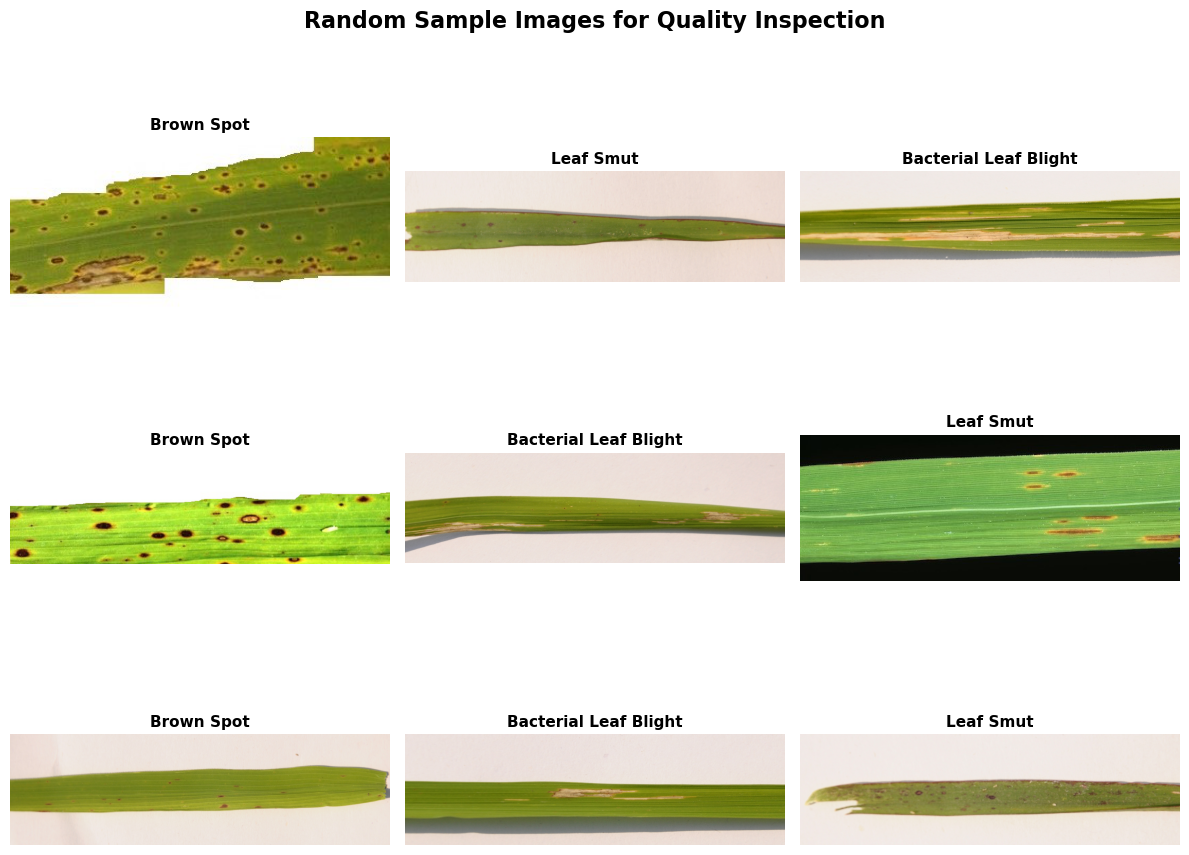

In [18]:
# Randomly select 9 images for visual quality inspection

sample_images = crops.sample(n=9)

plt.figure(figsize=(12,10))
for i, (_,row) in enumerate(sample_images.iterrows()):
    image = Image.open(row["Image_Path"])

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(row["Disease"], fontsize=11, fontweight="bold")
    plt.axis("off")

plt.suptitle(
    "Random Sample Images for Quality Inspection",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Observation:**

- Nine randomly selected images were visually inspected for quality.
- The rice leaves are clearly visible, and no severe blurring, extreme darkness, or overexposure was observed.
- The images have a [plain / uniform] background, so the leaf is the main object in the image.
- The disease-affected regions are visible, but the lesions are [small / spread across the leaf], so the model must learn fine local patterns.
- Some disease classes look visually similar, so confusion between classes is possible.
- Leaf orientation and position vary between images, so augmentation such as flipping and rotation may help the model generalize.
- Overall, the images are suitable for preprocessing and model development.

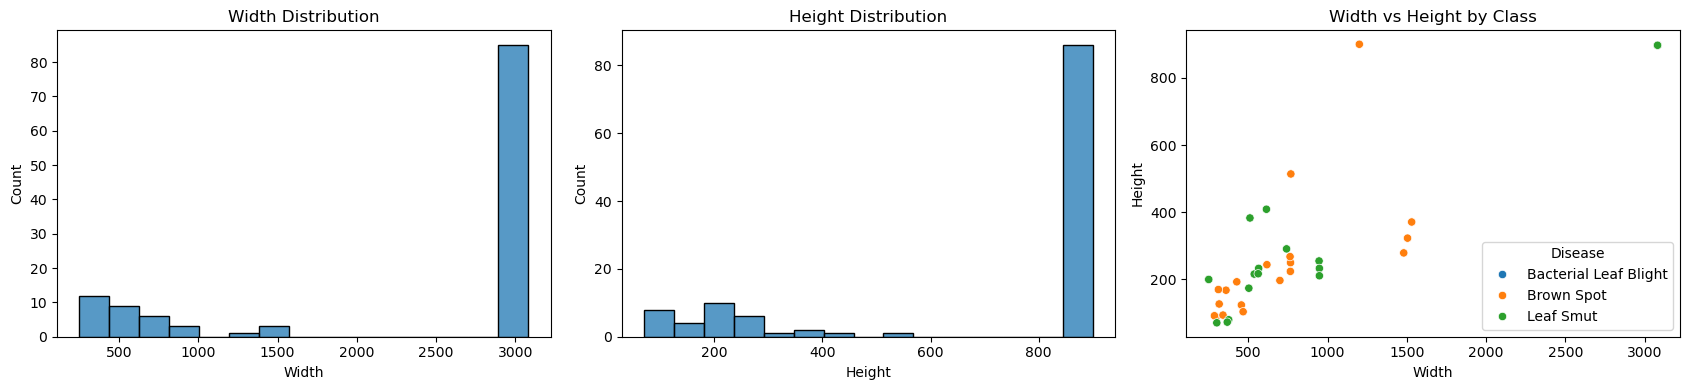

                         Width  Height  Aspect_Ratio  File_Size_KB
Disease                                                           
Bacterial Leaf Blight  3081.00  897.00          3.43        432.87
Brown Spot             1951.28  589.17          3.28        240.24
Leaf Smut              2111.85  635.23          3.25        248.73


In [19]:
# Dimension Analysis
image_info["Aspect_Ratio"] = image_info["Width"] / image_info["Height"]

fig, ax = plt.subplots(1, 3, figsize=(17, 4))

sns.histplot(image_info["Width"], bins=15, ax=ax[0])
ax[0].set_title("Width Distribution")

sns.histplot(image_info["Height"], bins=15, ax=ax[1])
ax[1].set_title("Height Distribution")

sns.scatterplot(data=image_info, x="Width", y="Height", hue="Disease", ax=ax[2])
ax[2].set_title("Width vs Height by Class")

plt.tight_layout()
plt.show()

print(image_info.groupby("Disease")[["Width", "Height", "Aspect_Ratio", "File_Size_KB"]].mean().round(2))

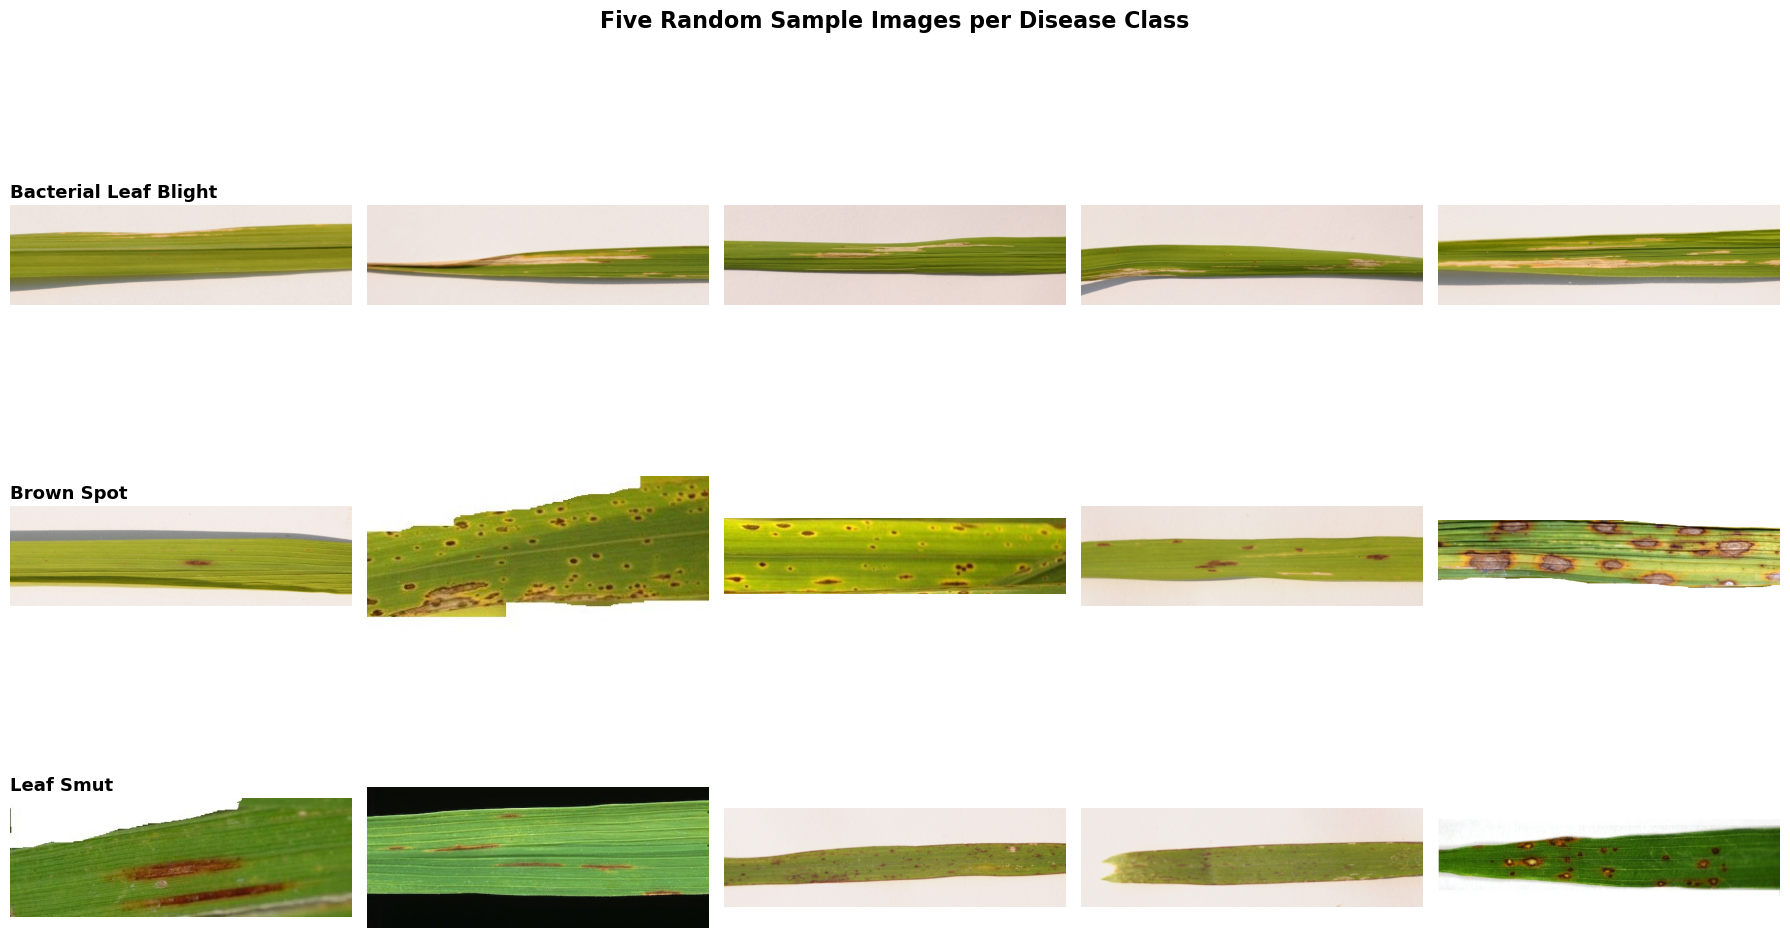

In [20]:
# Display 5 random sample images from each disease class

fig, axes = plt.subplots(3, 5, figsize=(18, 11))

for row_no, disease in enumerate(crops["Disease"].unique()):

    # Select 5 random images from the current disease class
    samples = crops[crops["Disease"] == disease].sample(5, random_state=42)

    for col_no, (_, row) in enumerate(samples.iterrows()):
        image = Image.open(row["Image_Path"])

        axes[row_no, col_no].imshow(image)
        axes[row_no, col_no].axis("off")

        # Show the disease name on the first image of each row
        if col_no == 0:
            axes[row_no, col_no].set_title(
                disease, fontsize=13, fontweight="bold", loc="left"
            )

plt.suptitle("Five Random Sample Images per Disease Class",
             fontsize=16, fontweight="bold")

plt.tight_layout()
plt.show()

Average Color Statistics by Disease Class:

                         Red  Green   Blue  Brightness  Contrast
Disease                                                         
Bacterial Leaf Blight  0.762  0.741  0.597       0.700     0.270
Brown Spot             0.750  0.743  0.497       0.663     0.277
Leaf Smut              0.706  0.713  0.554       0.658     0.262


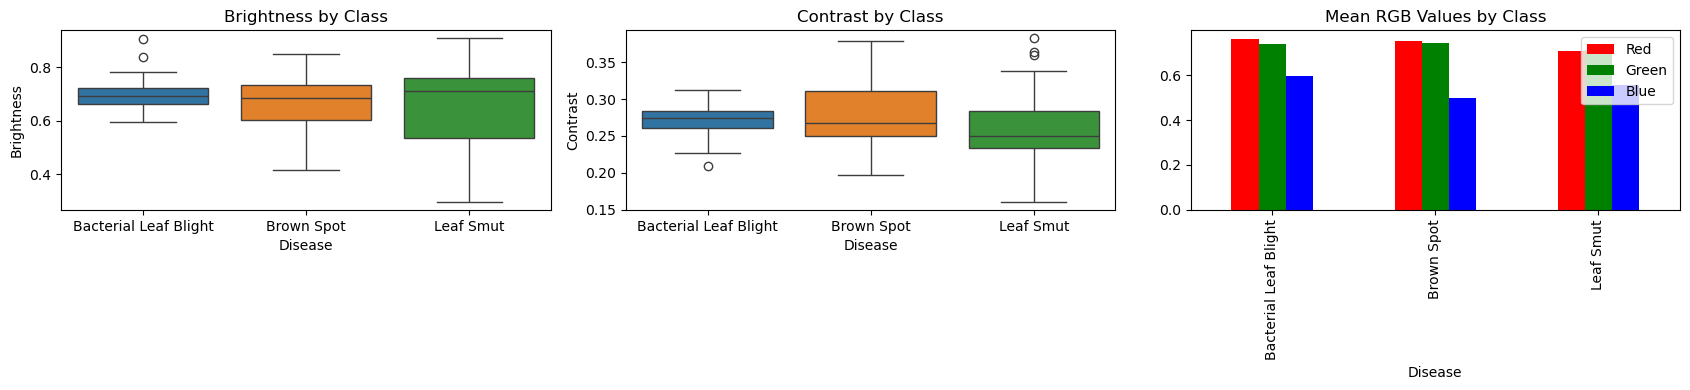

In [21]:
# Analyze brightness, contrast and color channels of each disease class

color_stats = []

for _, row in crops.iterrows():

    # Load the image, resize it and scale pixel values between 0 and 1
    image = Image.open(row["Image_Path"]).convert("RGB").resize((224, 224))
    img_array = np.array(image) / 255.0

    color_stats.append({
        "Disease": row["Disease"],
        "Red": img_array[:, :, 0].mean(),
        "Green": img_array[:, :, 1].mean(),
        "Blue": img_array[:, :, 2].mean(),
        "Brightness": img_array.mean(),
        "Contrast": img_array.std()
    })

# Create dataframe
color_df = pd.DataFrame(color_stats)

# Display average values for each class
print("Average Color Statistics by Disease Class:\n")
print(color_df.groupby("Disease").mean().round(3))

# Plot brightness, contrast and mean RGB values
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

sns.boxplot(data=color_df, x="Disease", y="Brightness",
            hue="Disease", ax=ax[0], legend=False)
ax[0].set_title("Brightness by Class")

sns.boxplot(data=color_df, x="Disease", y="Contrast",
            hue="Disease", ax=ax[1], legend=False)
ax[1].set_title("Contrast by Class")

color_df.groupby("Disease")[["Red", "Green", "Blue"]].mean().plot(
    kind="bar", color=["red", "green", "blue"], ax=ax[2])
ax[2].set_title("Mean RGB Values by Class")

plt.tight_layout()
plt.show()

## EDA Summary and Conclusion

The Exploratory Data Analysis (EDA) was performed to understand the rice leaf disease image dataset and identify its important characteristics before model development.

### Key Findings

1. **Dataset Size:** The dataset contains 119 images belonging to three rice leaf disease classes. The problem statement mentions 120 images (40 per   class), but the Leaf Smut class contains 39 images, so one image is missing from the provided data.

2. **Class Distribution:**
   - Bacterial Leaf Blight: 40 images
   - Brown Spot: 40 images
   - Leaf Smut: 39 images

   The dataset has a nearly balanced class distribution.

3. **Image Dimensions:** The images have different widths and heights, with 34 unique dimension combinations. Therefore, resizing is required before feeding images into the CNN model.

4. **Color Mode:** All 119 images are in RGB format, containing three color channels.

5. **Image Format:** All images are stored in JPEG format.

6. **File Size:** The average image file size is approximately 307.77 KB, with sizes ranging from 22.76 KB to 643.40 KB.

7. **Corrupted Image Check:** All 119 images passed the basic image integrity check. No corrupted images were detected.

8. **Duplicate Image Check:** No exact duplicate image files were found using MD5 hashing.

9. **Image Quality Inspection:** Randomly selected images were visually inspected. The sampled images appeared clear, with no obvious severe blurring, extreme darkness, or overexposure.

10. **Image Dimensions by Class:** Bacterial Leaf Blight images are noticeably larger (average width about 3081 px and file size about 433 KB) than Brown Spot (about 1951 px, 240 KB) and Leaf Smut (about 2112 px, 249 KB). This size difference could act as a shortcut that the model learns instead of the disease. Resizing all images to the same fixed size reduces this risk. All three classes have a similar wide aspect ratio (about 3.3:1), so a wide target size of 128 x 384 was chosen instead of a square size, to avoid distorting the leaf shape. This should be kept in mind during preprocessing.

11. **Color and Brightness Analysis:** Contrast is similar across all classes (0.26 to 0.28). Brightness is slightly higher for Bacterial Leaf Blight (0.700) than for Brown Spot (0.663) and Leaf Smut (0.658). The blue channel is lowest for Brown Spot (0.497), which may be partly due to its brown lesions and partly due to lighting differences. These differences are small to moderate, so the classes are not very different in color, but the model may be slightly influenced by lighting. This supports using brightness and contrast augmentation.
### EDA Conclusion

The EDA helped us understand the structure, distribution, and characteristics of the rice leaf image dataset. The dataset contains three nearly balanced disease classes, consistent JPEG format, and RGB images.

However, the images have different dimensions and file sizes. Therefore, image resizing and normalization will be important preprocessing steps before training the CNN model.

Overall, the dataset is suitable for proceeding with image preprocessing and deep learning model development.

# Task 2: Rice Leaf Disease Classification Model

**Task:** Create a model that can classify the three major diseases of rice plants: Leaf Smut, Brown Spot and Bacterial Leaf Blight.

The following sections cover data preprocessing, the train/validation/test split, CNN models built from scratch, and transfer learning with MobileNetV2. Each model is evaluated using test set metrics and 5-fold cross-validation.

## Data Preprocessing

In [22]:
# Define target image dimensions
# Original images are about 3.3 times wider than tall, so a wide size is used to avoid distortion

IMG_HEIGHT = 128
IMG_WIDTH = 384

print("Target Image Height:",IMG_HEIGHT )
print("Target Image Width:",IMG_WIDTH)

Target Image Height: 128
Target Image Width: 384


In [23]:
# Resize all images to the target dimensions

resized_images = []
image_labels = []

for _, row in crops.iterrows():
    image = Image.open(row["Image_Path"]).convert("RGB")
    image = image.resize((IMG_WIDTH, IMG_HEIGHT))
    resized_images.append(np.array(image))
    image_labels.append(row["Disease"])

print("Total Resizes Images:", len(resized_images))
print("Rotal Image Labels:", len(image_labels))
print("Resized Image Shape", resized_images[0].shape)

Total Resizes Images: 119
Rotal Image Labels: 119
Resized Image Shape (128, 384, 3)


In [24]:
# Convert resized image into a single numpy array
X = np.array(resized_images)

print("Shape of X:", X.shape)
print("Data Type of X:", X.dtype)

Shape of X: (119, 128, 384, 3)
Data Type of X: uint8


In [25]:
# Normalize image pixel values
X= X/255.0

print("Minimum Pixel Value:",X.min())
print("Maximum Pixel Value:", X.max())
print("Data Type of X", X.dtype)

Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0
Data Type of X float64


In [26]:
# Convert disease names into numerical labels
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(image_labels)

# Display disease name and its encoded label

for number, disease in enumerate(label_encoder.classes_):
    print(disease, ":", number)
    
# Display first 10 encoded labels and shape    
print("\nFirst 10 Encoded Labels:", y[:10])
print("Shape of y:", y.shape)

Bacterial Leaf Blight : 0
Brown Spot : 1
Leaf Smut : 2

First 10 Encoded Labels: [0 0 0 0 0 0 0 0 0 0]
Shape of y: (119,)


In [27]:
# verify image data and labels

print("Numbers of Image", len(X))
print("Numbers of Labels", len(y))

print("\nAre image and label count equal?", len(X)== len(y))
print("\nImage Data Shape:", X.shape)
print("Label Data Shape", y.shape)

Numbers of Image 119
Numbers of Labels 119

Are image and label count equal? True

Image Data Shape: (119, 128, 384, 3)
Label Data Shape (119,)


## Train, Validation and Test Split

In [28]:
# split dataset into training and temporary sets

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Images:", len(X_train))
print("Temporary Images:", len(X_temp))

print("\nTraining Labels:", len(y_train))
print("Temporary Labels:", len(y_temp))


Training Images: 95
Temporary Images: 24

Training Labels: 95
Temporary Labels: 24


In [29]:
# split temporary data into validation and testing sets

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Validation Images:", len(X_val))
print("Testing Image:", len(X_test))

print("\nValidation Labels:", len(y_val))
print("Testing Labels:", len(y_test))

Validation Images: 12
Testing Image: 12

Validation Labels: 12
Testing Labels: 12


In [30]:
# Verify the final datset split

print("Training Data Shape:", X_train.shape)
print("TrainingLabels Shape:", y_train.shape)

print("\nValidation Data Shape:", X_val.shape)
print("Validation Labels Shape:", y_val.shape)

print("\nTesting Data Shape:", X_test.shape)
print("Testing Labels Shape:", y_test.shape)

Training Data Shape: (95, 128, 384, 3)
TrainingLabels Shape: (95,)

Validation Data Shape: (12, 128, 384, 3)
Validation Labels Shape: (12,)

Testing Data Shape: (12, 128, 384, 3)
Testing Labels Shape: (12,)


In [31]:
# Check disease distribution in each dataset

print("Training Class Distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\n Validation Class Distribution:")
print(pd.Series(y_val).value_counts().sort_index())

print("Testing Class Distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training Class Distribution:
0    32
1    32
2    31
Name: count, dtype: int64

 Validation Class Distribution:
0    4
1    4
2    4
Name: count, dtype: int64
Testing Class Distribution:
0    4
1    4
2    4
Name: count, dtype: int64


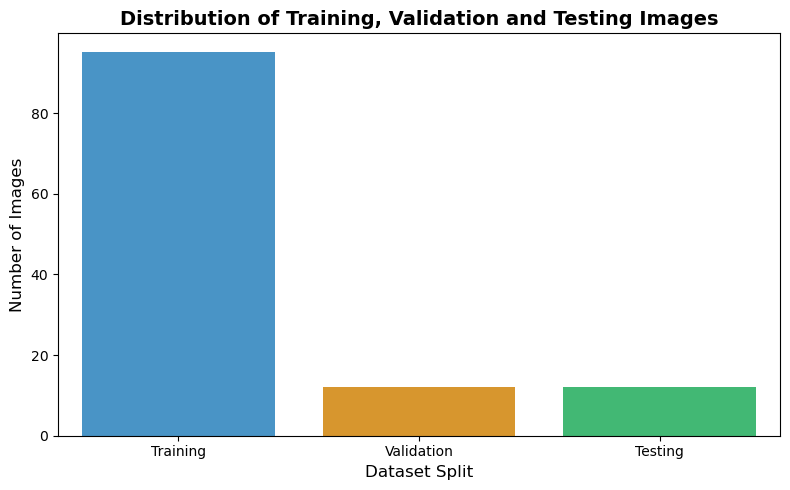

In [32]:
# Visualize the number of images in each dataset

split_counts = {
    "Training": len(X_train),
    "Validation": len(X_val),
    "Testing": len(X_test)
}

plt.figure(figsize=(8, 5))

sns.barplot(
    x=list(split_counts.keys()),
    y=list(split_counts.values()),
    hue=list(split_counts.keys()),
    palette=["#3498DB", "#F39C12", "#2ECC71"],
    legend=False
)

plt.title("Distribution of Training, Validation and Testing Images",
          fontsize=14, fontweight="bold")

plt.xlabel("Dataset Split", fontsize=12)
plt.ylabel("Number of Images", fontsize=12)

plt.tight_layout()
plt.show()

### Train, Validation and Test Split – Conclusion

The dataset was divided into training, validation, and testing sets using stratified sampling.

- Training Set: 95 images (80%)
- Validation Set: 12 images (10%)
- Testing Set: 12 images (10%)

Stratified splitting was used to maintain the proportion of all three disease classes across the datasets.

The final class distribution was verified, and all three disease classes were successfully represented in each dataset.

All images have a consistent shape of (128, 384, 3), and the corresponding labels were verified.

The dataset is now prepared for CNN model development.

**Note:** Due to the small dataset size, validation and test results may have considerable variation. Further evaluation with additional images would provide more reliable performance estimates.

## CNN Model Development

### Understanding CNN Architecture

Convolutional Neural Network (CNN) is a Deep Learning algorithm commonly used for image classification tasks.

In this project, CNN is used to identify and classify rice leaf diseases based on images.

The model will classify images into three categories:

- Bacterial Leaf Blight
- Brown Spot
- Leaf Smut

The CNN architecture consists of the following layers:

1. **Input Layer:** Accepts rice leaf images of size 128 × 384 × 3.
2. **Convolutional Layer (Conv2D):** Extracts important features such as edges, spots, textures, and patterns from images.
3. **Max Pooling Layer:** Reduces the spatial dimensions of feature maps while retaining important information.
4. **Flatten Layer:** Converts the extracted features into a one-dimensional vector.
5. **Dense Layer:** Learns patterns and relationships for classification.
6. **Output Layer:** Produces predictions for the three disease categories.

The basic CNN model will be developed first. Later, data augmentation will be applied to study its impact on model performance.

In [33]:
# Define input image shape and number of classes

INPUT_SHAPE = (IMG_HEIGHT, IMG_WIDTH, 3)
NUM_CLASSES = 3

print("Input Shape:", INPUT_SHAPE)
print("Number of Classes:", NUM_CLASSES)

Input Shape: (128, 384, 3)
Number of Classes: 3


### Build the CNN Mode

In [34]:
# Initialize a Sequential CNN model
cnn_model = keras.Sequential()

In [35]:
# Add the First Convolutional Layer
cnn_model.add(
    layers.Input(shape=INPUT_SHAPE)
)

# Add the first Convolutional Layer
cnn_model.add(
    layers.Conv2D(
        filters=32,
        kernel_size=(3,3),
        activation="relu",
  )
)

In [36]:
# Add the Max Pooling layer
cnn_model.add(
    layers.MaxPooling2D(
        pool_size=(2,2)
    )
)

In [37]:
# Add the Second Convelutional Layer

cnn_model.add(
    layers.Conv2D(
        filters=64,
        kernel_size=(3,3),
        activation="relu"
    )
)

In [38]:
# Add Second Max pooling Layer
cnn_model.add(
     layers.MaxPooling2D(
         pool_size=(2,2)
     )
 )

In [39]:
# Add Flatten Layer

cnn_model.add(
    layers.Flatten()
)

In [40]:
# Add the First Dense Layer
cnn_model.add(
    layers.Dense(
        units=128,
        activation="relu"
    )
)

In [41]:
# Add Dropout Layer

cnn_model.add(
    layers.Dropout(
        rate=0.5
    )
)

In [42]:
# Add the Output Layer

cnn_model.add(
    layers.Dense(
        units=NUM_CLASSES,
        activation="softmax"
    )
)

In [43]:
# Display CNN Model Summary
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 382, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 191, 32)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 189, 64)         │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 94, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 180480)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      23,101,568 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,121,347 (88.20 MB)

 Trainable params: 23,121,347 (88.20 MB)

 Non-trainable params: 0 (0.00 B)

### Observation: Flatten vs GlobalAveragePooling2D

The Flatten layer generated 180,480 values from the feature maps, resulting in about 23.1 million parameters in the Dense layer.

Since our dataset contains only 119 images, this large number of parameters may increase the risk of overfitting.

To reduce model complexity, GlobalAveragePooling2D is used instead. It reduces the feature maps to just 64 values, significantly decreasing the number of Dense layer parameters to 8,320.

Therefore, GlobalAveragePooling2D is selected for the baseline CNN architecture.

In [44]:
# Initialize the Baseline CNN model

baseline_cnn_model = keras.Sequential()

# Add the Input Layer
baseline_cnn_model.add(
    layers.Input(shape=INPUT_SHAPE)
)

# Add the first Convolutional Layer
baseline_cnn_model.add(
    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu"
    )
)

# Add the first Max Pooling Layer
baseline_cnn_model.add(
    layers.MaxPooling2D(
        pool_size=(2, 2)
    )
)

# Add the second Convolutional Layer
baseline_cnn_model.add(
    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu"
    )
)

# Add the second Max Pooling Layer
baseline_cnn_model.add(
    layers.MaxPooling2D(
        pool_size=(2, 2)
    )
)

# Add the Global Average Pooling Layer
baseline_cnn_model.add(
    layers.GlobalAveragePooling2D()
)

# Add the Dense Layer
baseline_cnn_model.add(
    layers.Dense(
        units=128,
        activation="relu"
    )
)

# Add the Dropout Layer
baseline_cnn_model.add(
    layers.Dropout(
        rate=0.5
    )
)

# Add the Output Layer
baseline_cnn_model.add(
    layers.Dense(
        units=NUM_CLASSES,
        activation="softmax"
    )
)

In [45]:
# Display the baseline CNN model summary

baseline_cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 126, 382, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 63, 191, 32)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 61, 189, 64)         │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 30, 94, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 64)                  │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 28,099 (109.76 KB)

 Trainable params: 28,099 (109.76 KB)

 Non-trainable params: 0 (0.00 B)

### Baseline CNN Model – Observation

The baseline CNN architecture uses GlobalAveragePooling2D instead of Flatten.

The total number of parameters has been reduced from 23,121,347 to 28,099.

This significantly reduces model complexity and may help control overfitting, especially with our small dataset of 119 images.

### Model Compilation

In [46]:
# Compile the baseline CNN model

baseline_cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [47]:
# Define callbacks to train longer and stop automatically at the best point

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=6,
    min_lr=1e-5
)

In [48]:
# train the Baseline CNN model

history = baseline_cnn_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    validation_data=(X_val,y_val),
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 334ms/step - accuracy: 0.3158 - loss: 1.1190 - val_accuracy: 0.3333 - val_loss: 1.0987 - learning_rate: 0.0010
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 241ms/step - accuracy: 0.3474 - loss: 1.1158 - val_accuracy: 0.3333 - val_loss: 1.0988 - learning_rate: 0.0010
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 275ms/step - accuracy: 0.3053 - loss: 1.1145 - val_accuracy: 0.3333 - val_loss: 1.0988 - learning_rate: 0.0010
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 239ms/step - accuracy: 0.4105 - loss: 1.0894 - val_accuracy: 0.3333 - val_loss: 1.0993 - learning_rate: 0.0010
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 236ms/step - accuracy: 0.4316 - loss: 1.0914 - val_accuracy: 0.4167 - val_loss: 1.0982 - learning_rate: 0.0010
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 231ms/step - accuracy: 0.3789 - loss: 1.0971 - val_accuracy: 0.5000 - val_loss: 1.0961 - learning_rate: 0.0010
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 245ms/step - accuracy: 0.4000 - loss: 1.

### Model Training – Observation

The baseline CNN model was trained for up to 100 epochs using the Adam optimizer with a batch size of 8. Early stopping and learning rate reduction were used to stop training automatically at the best point.

Training and validation accuracy showed some fluctuations across training runs. Both training and validation loss generally decreased, indicating that the model was learning patterns from the images.

The model's performance was limited, possibly due to the small dataset size. Further experiments using data augmentation will be performed to improve classification performance.

### Training Performance Visualization

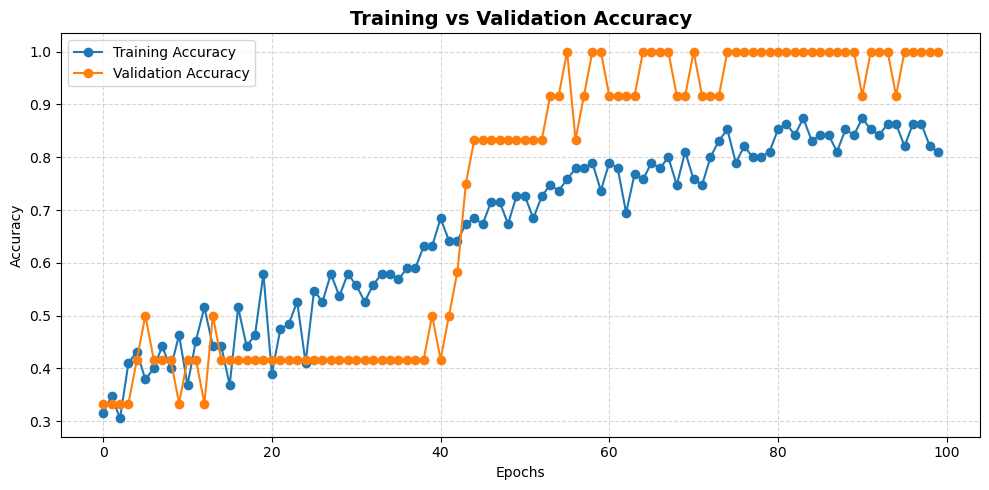

In [49]:
# Plot Training and Validation Accuracy

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("Training vs Validation Accuracy", fontsize=14, fontweight="bold")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

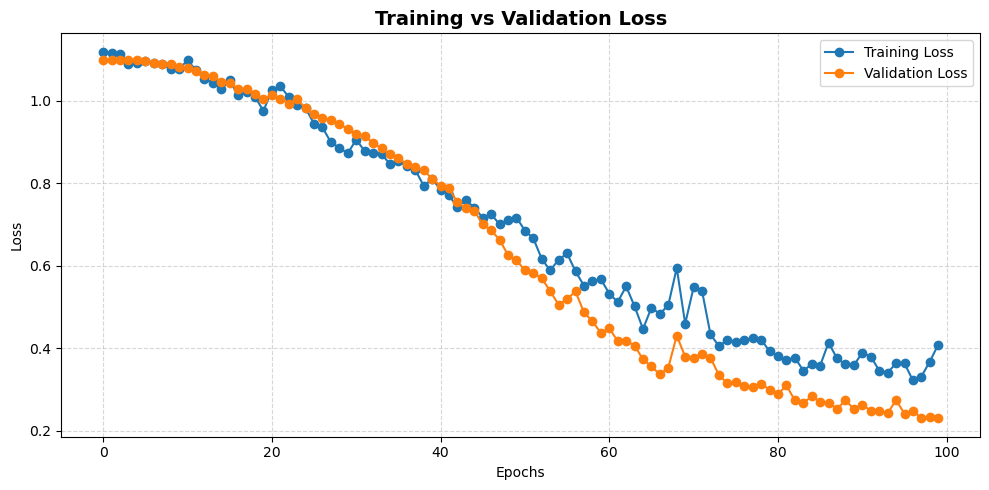

In [50]:
# Plot Training and Validation Loss

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("Training vs Validation Loss", fontsize=14, fontweight="bold")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Model Evaluation

In [51]:
# Generate predictions on the test dataset

y_pred_prob = baseline_cnn_model.predict(X_test)

# Convert probabilities into predicted class labels

y_pred = np.argmax(y_pred_prob, axis=1)

print("Actual Labels:   ", y_test)
print("Predicted Labels:", y_pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 367ms/step
Actual Labels:    [0 2 2 1 1 2 0 1 0 1 0 2]
Predicted Labels: [0 2 2 0 1 2 0 1 0 1 1 2]


In [52]:
# Calculate test accuracy

test_accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Test Accuracy: 83.33 %


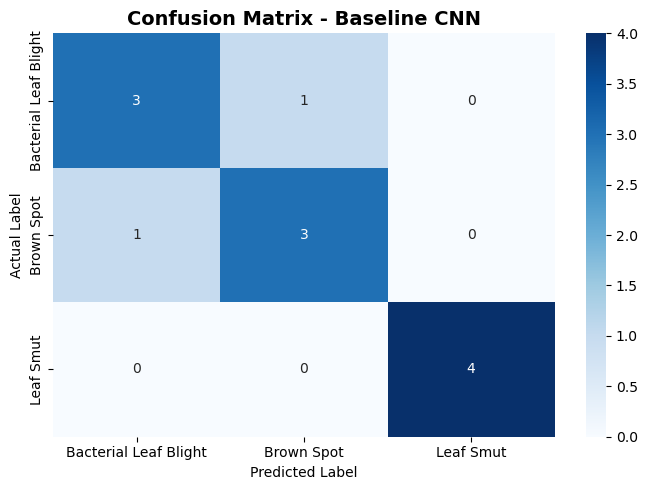

In [53]:
# Generate Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

# Display Confusion Matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - Baseline CNN", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

## Data Augmentation Experiment

### Understanding Data Augmentation

Data Augmentation is a technique used to artificially increase the diversity of training images by applying transformations such as flipping, rotation, and zooming.

In this project, data augmentation will be applied to training images to help the CNN model learn different variations of rice leaf images.

The objective is to investigate whether data augmentation improves the model's ability to classify rice leaf diseases and generalize to unseen images.

In [54]:
# Define the data augmentation pipeline
# Mild settings are used so that the leaf shape and lesions stay realistic

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.03, fill_mode="nearest"),   # about ±11 degrees
    layers.RandomZoom(0.1, fill_mode="nearest")
])

#### Visualize augmented images

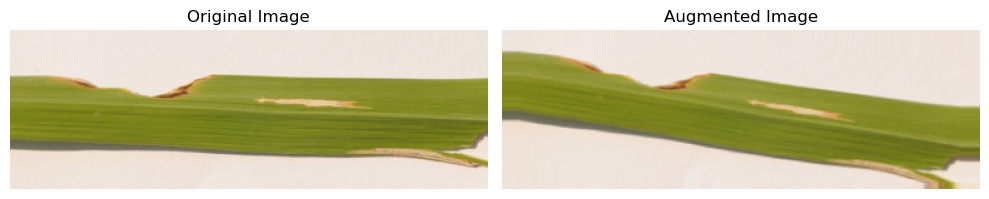

In [55]:
# select one image from the training dataset
sample_image = X_train[0]

#Add batch dimension
sample_image_batch = np.expand_dims(sample_image, axis=0)

#Apply data augmentation
augmented_image = data_augmentation(sample_image_batch, training=True)

# Display original and augmented images
plt.figure(figsize=(10,4))

plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(sample_image)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(augmented_image[0].numpy())
plt.title("Augmented Image")
plt.axis("off")

plt.tight_layout()
plt.show()

#### Build the Augmented CNN Model

In [56]:
# Initialize the augmented CNN model

augmented_cnn_model = keras.Sequential()

# Add the Input Layer
augmented_cnn_model.add(
    layers.Input(shape=INPUT_SHAPE)
)

# Add the Data Augmentation Layer
augmented_cnn_model.add(data_augmentation)

# Add the first Convolutional Layer
augmented_cnn_model.add(
    layers.Conv2D(32, (3, 3), activation="relu")
)

# Add the first Max Pooling Layer
augmented_cnn_model.add(
    layers.MaxPooling2D((2, 2))
)

# Add the second Convolutional Layer
augmented_cnn_model.add(
    layers.Conv2D(64, (3, 3), activation="relu")
)

# Add the second Max Pooling Layer
augmented_cnn_model.add(
    layers.MaxPooling2D((2, 2))
)

# Add the Global Average Pooling Layer
augmented_cnn_model.add(
    layers.GlobalAveragePooling2D()
)

# Add the Dense Layer
augmented_cnn_model.add(
    layers.Dense(128, activation="relu")
)

# Add the Dropout Layer
augmented_cnn_model.add(
    layers.Dropout(0.5)
)

# Add the Output Layer
augmented_cnn_model.add(
    layers.Dense(NUM_CLASSES, activation="softmax")
)

In [57]:
# Display the augmented CNN model architecture

augmented_cnn_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)            │ (None, 128, 384, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 126, 382, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 63, 191, 32)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 61, 189, 64)         │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 30, 94, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 64)                  │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 28,099 (109.76 KB)

 Trainable params: 28,099 (109.76 KB)

 Non-trainable params: 0 (0.00 B)

In [58]:
# Compile the augmented CNN model

augmented_cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [59]:
# Train the augmented CNN model

augmented_history = augmented_cnn_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    validation_data=(X_val, y_val),
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 384ms/step - accuracy: 0.3684 - loss: 1.1469 - val_accuracy: 0.3333 - val_loss: 1.0988 - learning_rate: 0.0010
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 241ms/step - accuracy: 0.3053 - loss: 1.1098 - val_accuracy: 0.3333 - val_loss: 1.0999 - learning_rate: 0.0010
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 248ms/step - accuracy: 0.3263 - loss: 1.1170 - val_accuracy: 0.3333 - val_loss: 1.0998 - learning_rate: 0.0010
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 246ms/step - accuracy: 0.3263 - loss: 1.1049 - val_accuracy: 0.5000 - val_loss: 1.0989 - learning_rate: 0.0010
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 247ms/step - accuracy: 0.2737 - loss: 1.1175 - val_accuracy: 0.3333 - val_loss: 1.0954 - learning_rate: 0.0010
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 253ms/step - accuracy: 0.3579 - loss: 1.0942 - val_accuracy: 0.5000 - val_loss: 1.0943 - learning_rate: 0.0010
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 243ms/step - accuracy: 0.3789 - loss: 1.

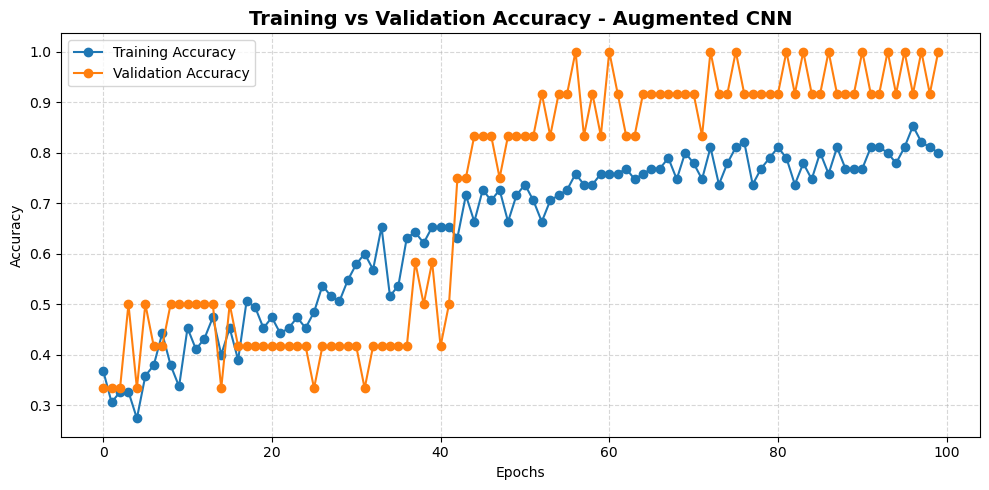

In [60]:
# Plot training and validation accuracy

plt.figure(figsize=(10, 5))

plt.plot(
    augmented_history.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    augmented_history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("Training vs Validation Accuracy - Augmented CNN",
          fontsize=14, fontweight="bold")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

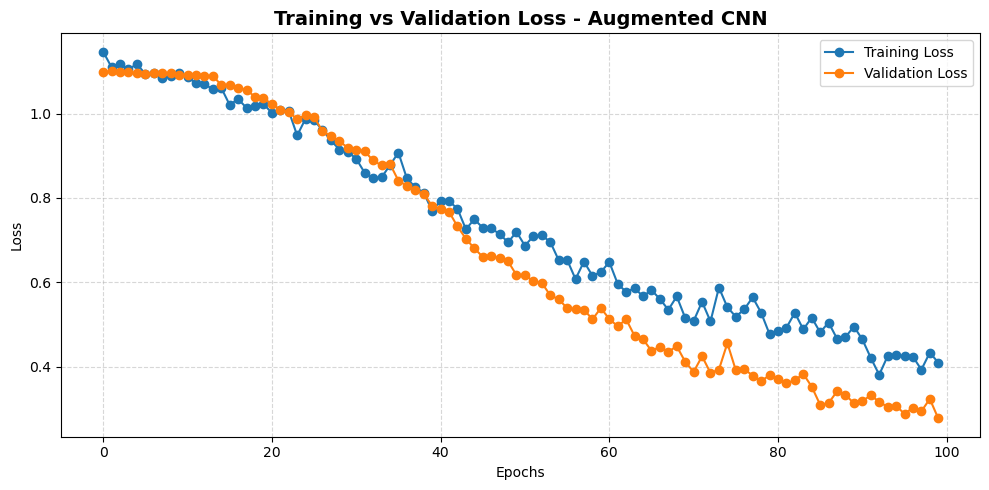

In [61]:
# Plot training and validation loss

plt.figure(figsize=(10, 5))

plt.plot(
    augmented_history.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    augmented_history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("Training vs Validation Loss - Augmented CNN",
          fontsize=14, fontweight="bold")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [62]:
# Generate predictions on the test dataset

augmented_y_pred_prob = augmented_cnn_model.predict(X_test)

# Convert probabilities into predicted class labels

augmented_y_pred = np.argmax(augmented_y_pred_prob, axis=1)

print("Actual Labels:   ", y_test)
print("Predicted Labels:", augmented_y_pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step
Actual Labels:    [0 2 2 1 1 2 0 1 0 1 0 2]
Predicted Labels: [0 2 2 0 1 2 0 1 0 0 0 2]


In [63]:
# Calculate test accuracy of augmented CNN

augmented_test_accuracy = accuracy_score(
    y_test,
    augmented_y_pred
)

print(
    "Augmented CNN Test Accuracy:",
    round(augmented_test_accuracy * 100, 2),
    "%"
)

Augmented CNN Test Accuracy: 83.33 %


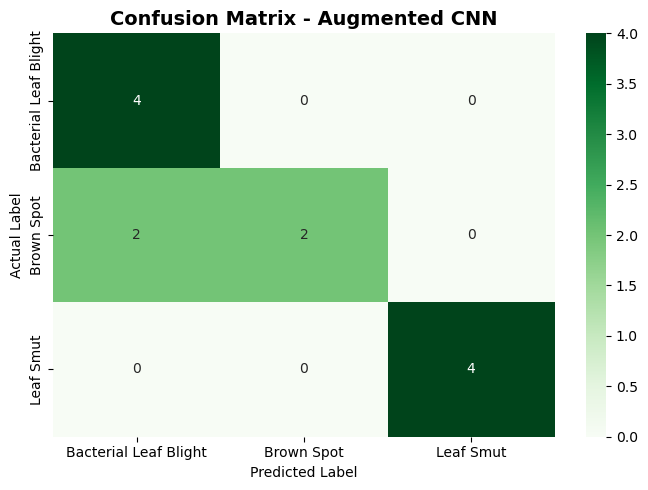

In [64]:
# Generate confusion matrix for augmented CNN

augmented_cm = confusion_matrix(
    y_test,
    augmented_y_pred
)

# Visualize confusion matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    augmented_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title(
    "Confusion Matrix - Augmented CNN",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [65]:
# Generate classification report for augmented CNN

print(
    classification_report(
        y_test,
        augmented_y_pred,
        target_names=label_encoder.classes_
    )
)

                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.67      1.00      0.80         4
           Brown Spot       1.00      0.50      0.67         4
            Leaf Smut       1.00      1.00      1.00         4

             accuracy                           0.83        12
            macro avg       0.89      0.83      0.82        12
         weighted avg       0.89      0.83      0.82        12



In [66]:
# Compare the performance of both CNN models

model_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],

    "Baseline CNN": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, average="macro", zero_division=0),
        recall_score(y_test, y_pred, average="macro", zero_division=0),
        f1_score(y_test, y_pred, average="macro", zero_division=0)
    ],

    "Augmented CNN": [
        accuracy_score(y_test, augmented_y_pred),
        precision_score(y_test, augmented_y_pred, average="macro", zero_division=0),
        recall_score(y_test, augmented_y_pred, average="macro", zero_division=0),
        f1_score(y_test, augmented_y_pred, average="macro", zero_division=0)
    ]
})

# Display comparison table

model_comparison.round(4)

,Metric,Baseline CNN,Augmented CNN
0,Accuracy,0.8333,0.8333
1,Precision,0.8333,0.8889
2,Recall,0.8333,0.8333
3,F1-Score,0.8333,0.8222


In [67]:
# Compare predictions from both models

print("Baseline CNN Predictions:", y_pred)
print("Augmented CNN Predictions:", augmented_y_pred)

print("\nAre both predictions identical?",
      np.array_equal(y_pred, augmented_y_pred))

print("\nBaseline CNN Accuracy:",
      accuracy_score(y_test, y_pred))

print("Augmented CNN Accuracy:",
      accuracy_score(y_test, augmented_y_pred))

Baseline CNN Predictions: [0 2 2 0 1 2 0 1 0 1 1 2]
Augmented CNN Predictions: [0 2 2 0 1 2 0 1 0 0 0 2]

Are both predictions identical? False

Baseline CNN Accuracy: 0.8333333333333334
Augmented CNN Accuracy: 0.8333333333333334


In [68]:
# Generate fresh predictions from Baseline CNN

baseline_prob =baseline_cnn_model.predict(X_test)
baseline_predictions = np.argmax(baseline_prob, axis=1)


# Generate fresh predictions from Augmented CNN

augmented_prob = augmented_cnn_model.predict(X_test)
augmented_predictions = np.argmax(augmented_prob, axis=1)


# Compare both predictions

print("Baseline CNN:", baseline_predictions)
print("Augmented CNN:", augmented_predictions)

print("\nAre predictions identical?",
      np.array_equal(baseline_predictions, augmented_predictions))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
Baseline CNN: [0 2 2 0 1 2 0 1 0 1 1 2]
Augmented CNN: [0 2 2 0 1 2 0 1 0 0 0 2]

Are predictions identical? False


In [69]:
# Compare prediction probabilities of both models

probability_comparison = pd.DataFrame({
    "Actual Label": y_test,
    "Baseline CNN Prediction": baseline_predictions,
    "Augmented CNN Prediction": augmented_predictions,
    "Baseline CNN Max Probability": np.max(baseline_prob, axis=1),
    "Augmented CNN Max Probability": np.max(augmented_prob, axis=1)
})

probability_comparison.round(4)

,Actual Label,Baseline CNN Prediction,Augmented CNN Prediction,Baseline CNN Max Probability,Augmented CNN Max Probability
0,0,0,0,0.9726,0.9801
1,2,2,2,0.9973,0.9998
2,2,2,2,0.6020,0.6864
3,1,0,0,0.5522,0.7057
4,1,1,1,1.0000,1.0000
5,2,2,2,0.5920,0.6059
6,0,0,0,0.7729,0.8448
7,1,1,1,1.0000,1.0000
8,0,0,0,0.8259,0.8344
9,1,1,0,0.5305,0.6814


In [70]:
# Final comparison of both CNN models

model_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],

    "Baseline CNN": [
        accuracy_score(y_test, baseline_predictions),
        precision_score(y_test, baseline_predictions, average="macro", zero_division=0),
        recall_score(y_test, baseline_predictions, average="macro", zero_division=0),
        f1_score(y_test, baseline_predictions, average="macro", zero_division=0)
    ],

    "Augmented CNN": [
        accuracy_score(y_test, augmented_predictions),
        precision_score(y_test, augmented_predictions, average="macro", zero_division=0),
        recall_score(y_test, augmented_predictions, average="macro", zero_division=0),
        f1_score(y_test, augmented_predictions, average="macro", zero_division=0)
    ]
})

model_comparison.round(4)

,Metric,Baseline CNN,Augmented CNN
0,Accuracy,0.8333,0.8333
1,Precision,0.8333,0.8889
2,Recall,0.8333,0.8333
3,F1-Score,0.8333,0.8222


## Cross-Validation Comparison

Because the test set contains only 12 images, a single train-test split gives an unreliable comparison. Stratified 5-fold cross-validation is used so that all 119 images are used for testing once.

In [71]:
# Compare Baseline CNN and Augmented CNN using 5-fold cross-validation

from sklearn.model_selection import StratifiedKFold
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Function to build the CNN (with or without data augmentation)
def build_cnn(use_augmentation=False):
    model = keras.Sequential()
    model.add(layers.Input(shape=INPUT_SHAPE))

    if use_augmentation:
        model.add(data_augmentation)

    model.add(layers.Conv2D(32, (3, 3), activation="relu"))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(64, (3, 3), activation="relu"))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dense(128, activation="relu"))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(NUM_CLASSES, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {"Baseline CNN": [], "Augmented CNN": []}

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):

    # Split the training part again to get a validation set
    X_tr, X_va, y_tr, y_va = train_test_split(
        X[train_idx], y[train_idx],
        test_size=0.15, random_state=42, stratify=y[train_idx]
    )

    for name, use_aug in [("Baseline CNN", False), ("Augmented CNN", True)]:

        keras.backend.clear_session()
        tf.keras.utils.set_random_seed(42)

        model = build_cnn(use_augmentation=use_aug)

        model.fit(
            X_tr, y_tr,
            epochs=60,
            batch_size=8,
            validation_data=(X_va, y_va),
            callbacks=[
                EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
                ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)
            ],
            verbose=0
        )

        accuracy = model.evaluate(X[test_idx], y[test_idx], verbose=0)[1]
        cv_results[name].append(accuracy)

        print(f"Fold {fold} - {name}: {accuracy:.4f}")

# Display mean and standard deviation of all folds
print("\nCross-Validation Summary:\n")
for name, scores in cv_results.items():
    print(f"{name}: Mean Accuracy = {np.mean(scores):.4f}, Std = {np.std(scores):.4f}")


Fold 1 - Baseline CNN: 0.4167
Fold 1 - Augmented CNN: 0.2917
Fold 2 - Baseline CNN: 0.7500
Fold 2 - Augmented CNN: 0.7500
Fold 3 - Baseline CNN: 0.3333
Fold 3 - Augmented CNN: 0.3333
Fold 4 - Baseline CNN: 0.4167
Fold 4 - Augmented CNN: 0.3333
Fold 5 - Baseline CNN: 0.3913
Fold 5 - Augmented CNN: 0.3913

Cross-Validation Summary:

Baseline CNN: Mean Accuracy = 0.4616, Std = 0.1474
Augmented CNN: Mean Accuracy = 0.4199, Std = 0.1681


## Transfer Learning with MobileNetV2

The CNN trained from scratch achieved only about 46% mean accuracy in cross-validation because the dataset is very small. A MobileNetV2 model pretrained on ImageNet is used as a feature extractor, so the model starts with already-learned features such as edges, textures, and shapes.

In [72]:
# Build a transfer learning model using pretrained MobileNetV2

# Load MobileNetV2 without its top classification layers
base_model = keras.applications.MobileNetV2(
    input_shape=INPUT_SHAPE,
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers so their learned features are kept
base_model.trainable = False

def build_transfer_model():
    inputs = layers.Input(shape=INPUT_SHAPE)

    # Convert pixel values from 0-1 to -1 to 1, as MobileNetV2 expects
    x = layers.Rescaling(2.0, offset=-1)(inputs)

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = keras.Model(inputs, outputs)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

transfer_model = build_transfer_model()
transfer_model.summary()

C:\Users\admin\AppData\Local\Temp\ipykernel_13540\3222755948.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = keras.applications.MobileNetV2(


Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)           │ (None, 128, 384, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 128, 384, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 4, 12, 1280)         │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │           3,843 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [73]:
# Train the transfer learning model

transfer_history = transfer_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=8,
    validation_data=(X_val, y_val),
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)
    ]
)

# Evaluate on the test dataset
transfer_pred = np.argmax(transfer_model.predict(X_test), axis=1)

print("Actual Labels:   ", y_test)
print("Predicted Labels:", transfer_pred)
print("Transfer Learning Test Accuracy:",
      round(accuracy_score(y_test, transfer_pred) * 100, 2), "%")

Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 10s 402ms/step - accuracy: 0.4211 - loss: 1.3115 - val_accuracy: 0.5833 - val_loss: 0.6595 - learning_rate: 0.0010
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 221ms/step - accuracy: 0.7053 - loss: 0.7601 - val_accuracy: 0.8333 - val_loss: 0.3564 - learning_rate: 0.0010
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 221ms/step - accuracy: 0.7684 - loss: 0.5491 - val_accuracy: 0.9167 - val_loss: 0.2775 - learning_rate: 0.0010
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 221ms/step - accuracy: 0.8632 - loss: 0.3758 - val_accuracy: 0.9167 - val_loss: 0.2269 - learning_rate: 0.0010
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 224ms/step - accuracy: 0.9158 - loss: 0.3089 - val_accuracy: 0.9167 - val_loss: 0.2216 - learning_rate: 0.0010
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 221ms/step - accuracy: 0.9158 - loss: 0.2475 - val_accuracy: 0.9167 - val_loss: 0.2097 - learning_rate: 0.0010
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 222ms/step - accuracy: 0.9684 - loss: 0.1793 -

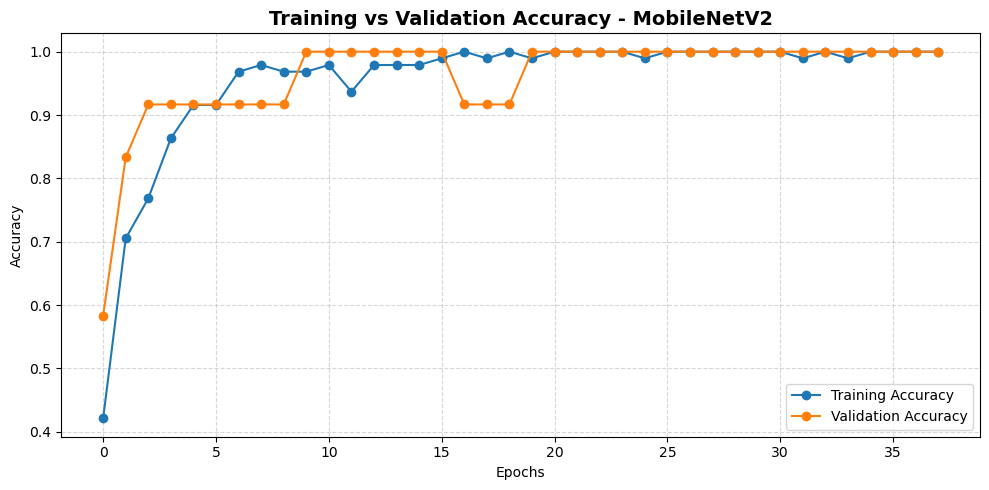

In [74]:
# Plot Training and Validation Accuracy - MobileNetV2

plt.figure(figsize=(10, 5))

plt.plot(
    transfer_history.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    transfer_history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("Training vs Validation Accuracy - MobileNetV2", fontsize=14, fontweight="bold")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

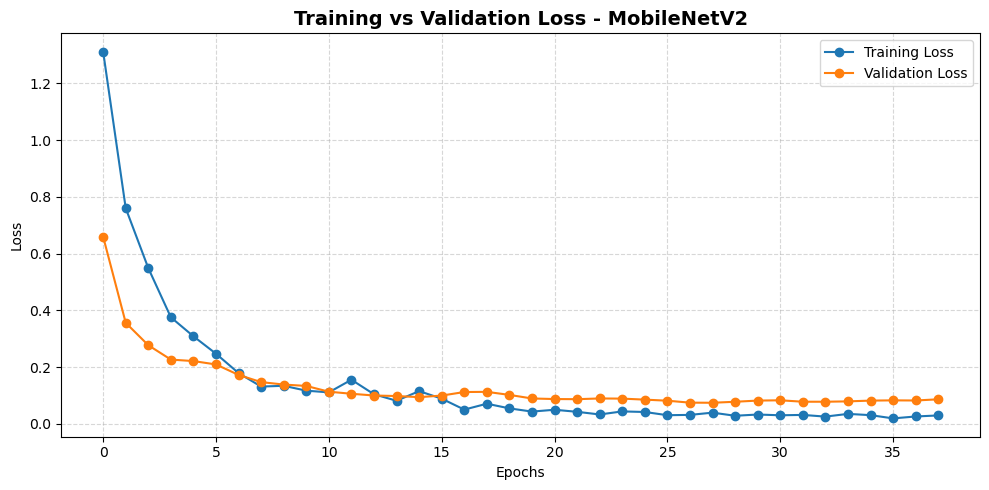

In [75]:
# Plot Training and Validation Loss - MobileNetV2

plt.figure(figsize=(10, 5))

plt.plot(
    transfer_history.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    transfer_history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("Training vs Validation Loss - MobileNetV2", fontsize=14, fontweight="bold")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Cross-Validation: MobileNetV2 with and without Data Augmentation

Stratified 5-fold cross-validation is used again so that MobileNetV2 can be compared fairly with the scratch CNNs, and so the effect of data augmentation on the pretrained model can be measured.

In [76]:
# Compare MobileNetV2 with and without data augmentation using 5-fold cross-validation

def build_transfer_cv_model(use_augmentation=False):
    inputs = layers.Input(shape=INPUT_SHAPE)

    # Apply data augmentation only for the augmented version
    x = data_augmentation(inputs) if use_augmentation else inputs

    # Convert pixel values from 0-1 to -1 to 1, as MobileNetV2 expects
    x = layers.Rescaling(2.0, offset=-1)(x)

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

tl_cv_results = {"MobileNetV2": [], "MobileNetV2 + Augmentation": []}

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):

    # Split the training part again to get a validation set
    X_tr, X_va, y_tr, y_va = train_test_split(
        X[train_idx], y[train_idx],
        test_size=0.15, random_state=42, stratify=y[train_idx]
    )

    for name, use_aug in [("MobileNetV2", False), ("MobileNetV2 + Augmentation", True)]:

        tf.keras.utils.set_random_seed(42)

        model = build_transfer_cv_model(use_augmentation=use_aug)

        model.fit(
            X_tr, y_tr,
            epochs=30,
            batch_size=8,
            validation_data=(X_va, y_va),
            callbacks=[
                EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
                ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)
            ],
            verbose=0
        )

        accuracy = model.evaluate(X[test_idx], y[test_idx], verbose=0)[1]
        tl_cv_results[name].append(accuracy)

        print(f"Fold {fold} - {name}: {accuracy:.4f}")

# Display mean and standard deviation of all folds
print("\nTransfer Learning Cross-Validation Summary:\n")
for name, scores in tl_cv_results.items():
    print(f"{name}: Mean Accuracy = {np.mean(scores):.4f}, Std = {np.std(scores):.4f}")

Fold 1 - MobileNetV2: 1.0000
Fold 1 - MobileNetV2 + Augmentation: 1.0000
Fold 2 - MobileNetV2: 0.8333
Fold 2 - MobileNetV2 + Augmentation: 0.7917
Fold 3 - MobileNetV2: 0.9583
Fold 3 - MobileNetV2 + Augmentation: 0.9583
Fold 4 - MobileNetV2: 0.8750
Fold 4 - MobileNetV2 + Augmentation: 0.9167
Fold 5 - MobileNetV2: 0.8261
Fold 5 - MobileNetV2 + Augmentation: 0.7391

Transfer Learning Cross-Validation Summary:

MobileNetV2: Mean Accuracy = 0.8986, Std = 0.0692
MobileNetV2 + Augmentation: Mean Accuracy = 0.8812, Std = 0.0995


### MobileNetV2 with Data Augmentation

The augmented MobileNetV2 is trained once on the original train/validation split so that its training curves and test results can be compared with the MobileNetV2 model without augmentation.

In [77]:
# Train MobileNetV2 with data augmentation on the original train/validation split

tf.keras.utils.set_random_seed(42)

transfer_aug_model = build_transfer_cv_model(use_augmentation=True)

transfer_aug_history = transfer_aug_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=8,
    validation_data=(X_val, y_val),
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)
    ]
)

# Evaluate on the test dataset
transfer_aug_pred = np.argmax(transfer_aug_model.predict(X_test), axis=1)

print("Actual Labels:   ", y_test)
print("Predicted Labels:", transfer_aug_pred)
print("MobileNetV2 + Augmentation Test Accuracy:",
      round(accuracy_score(y_test, transfer_aug_pred) * 100, 2), "%")

Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 12s 482ms/step - accuracy: 0.4000 - loss: 1.4314 - val_accuracy: 0.6667 - val_loss: 0.6934 - learning_rate: 0.0010
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 291ms/step - accuracy: 0.5158 - loss: 0.9595 - val_accuracy: 1.0000 - val_loss: 0.3940 - learning_rate: 0.0010
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 296ms/step - accuracy: 0.6947 - loss: 0.7787 - val_accuracy: 1.0000 - val_loss: 0.3101 - learning_rate: 0.0010
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 297ms/step - accuracy: 0.7684 - loss: 0.6078 - val_accuracy: 1.0000 - val_loss: 0.2451 - learning_rate: 0.0010
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 301ms/step - accuracy: 0.7789 - loss: 0.5514 - val_accuracy: 1.0000 - val_loss: 0.2174 - learning_rate: 0.0010
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 274ms/step - accuracy: 0.8105 - loss: 0.4032 - val_accuracy: 1.0000 - val_loss: 0.2314 - learning_rate: 0.0010
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 279ms/step - accuracy: 0.8632 - loss: 0.3392 -

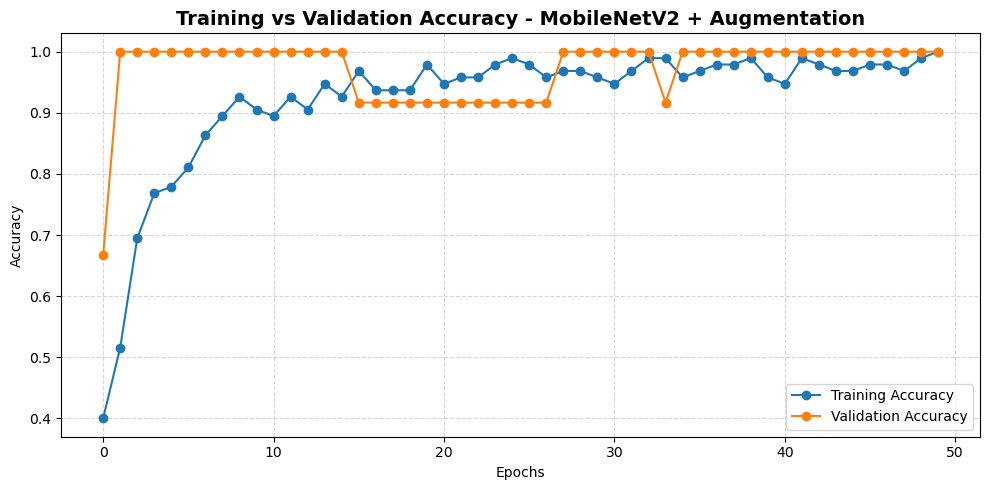

In [78]:
# Plot Training and Validation Accuracy - MobileNetV2 + Augmentation

plt.figure(figsize=(10, 5))

plt.plot(
    transfer_aug_history.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    transfer_aug_history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("Training vs Validation Accuracy - MobileNetV2 + Augmentation",
          fontsize=14, fontweight="bold")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

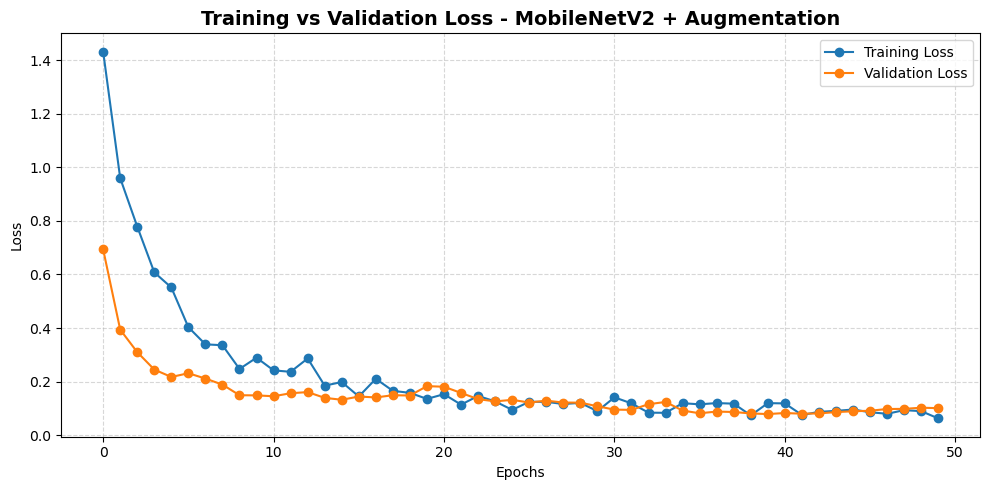

In [79]:
# Plot Training and Validation Loss - MobileNetV2 + Augmentation

plt.figure(figsize=(10, 5))

plt.plot(
    transfer_aug_history.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    transfer_aug_history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("Training vs Validation Loss - MobileNetV2 + Augmentation",
          fontsize=14, fontweight="bold")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Model Comparison Report

**Task:** Create a report stating the performance of multiple models on this data and suggest the best model for production.

The following sections compare the Baseline CNN, Augmented CNN, MobileNetV2 and MobileNetV2 with augmentation using test set metrics and 5-fold cross-validation, followed by a conclusion that recommends the best model for production.

## Final Model Comparison

All four models are compared using test set metrics and 5-fold cross-validation. Cross-validation is the more reliable measure because the test set contains only 12 images.

In [80]:
# Final comparison of all models (test set metrics and cross-validation results)

# Store the predictions of every model
all_predictions = {
    "Baseline CNN": baseline_predictions,
    "Augmented CNN": augmented_predictions,
    "MobileNetV2": transfer_pred,
    "MobileNetV2 + Augmentation": transfer_aug_pred
}

# Cross-validation scores (taken in the same order the models were evaluated)
cv_scores = {
    "Baseline CNN": list(cv_results.values())[0],
    "Augmented CNN": list(cv_results.values())[1],
    "MobileNetV2": tl_cv_results["MobileNetV2"],
    "MobileNetV2 + Augmentation": tl_cv_results["MobileNetV2 + Augmentation"]
}

rows = []

for model_name, preds in all_predictions.items():
    rows.append({
        "Model": model_name,
        "Test Accuracy": accuracy_score(y_test, preds),
        "Test Precision": precision_score(y_test, preds, average="macro", zero_division=0),
        "Test Recall": recall_score(y_test, preds, average="macro", zero_division=0),
        "Test F1-Score": f1_score(y_test, preds, average="macro", zero_division=0),
        "CV Mean Accuracy": np.mean(cv_scores[model_name]),
        "CV Std": np.std(cv_scores[model_name])
    })

final_comparison = pd.DataFrame(rows)

# Display the table
final_comparison.round(4)

,Model,Test Accuracy,Test Precision,Test Recall,Test F1-Score,CV Mean Accuracy,CV Std
0,Baseline CNN,0.8333,0.8333,0.8333,0.8333,0.4616,0.1474
1,Augmented CNN,0.8333,0.8889,0.8333,0.8222,0.4199,0.1681
2,MobileNetV2,0.9167,0.9333,0.9167,0.9153,0.8986,0.0692
3,MobileNetV2 + Augmentation,0.9167,0.9333,0.9167,0.9153,0.8812,0.0995


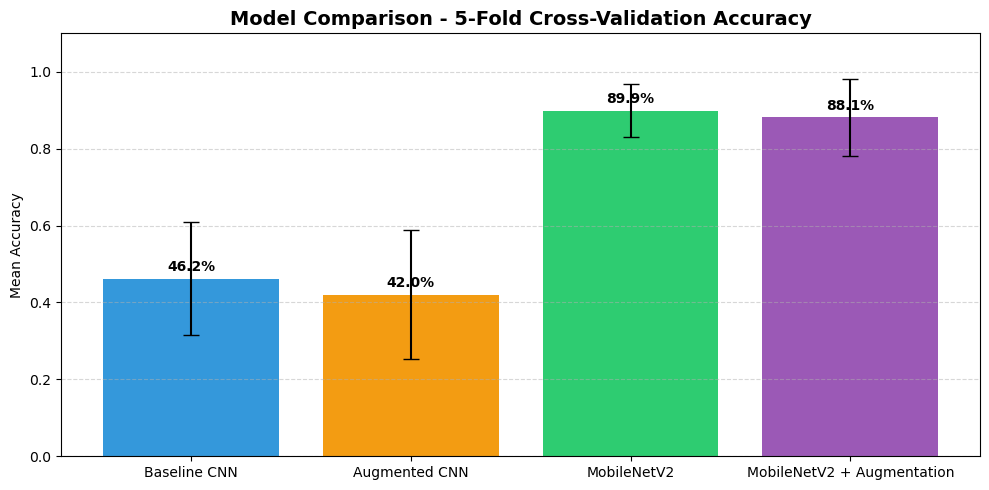

In [81]:
# Plot cross-validation accuracy of all models

plt.figure(figsize=(10, 5))

bars = plt.bar(
    final_comparison["Model"],
    final_comparison["CV Mean Accuracy"],
    yerr=final_comparison["CV Std"],
    capsize=6,
    color=["#3498DB", "#F39C12", "#2ECC71", "#9B59B6"]
)

# Show the accuracy value on top of each bar
for bar, value in zip(bars, final_comparison["CV Mean Accuracy"]):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 0.02,
             f"{value * 100:.1f}%", ha="center", fontweight="bold")

plt.title("Model Comparison - 5-Fold Cross-Validation Accuracy",
          fontsize=14, fontweight="bold")
plt.ylabel("Mean Accuracy")
plt.ylim(0, 1.1)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Model Comparison Conclusion

Four models were compared on the rice leaf disease dataset: a Baseline CNN, an Augmented CNN, MobileNetV2, and MobileNetV2 with data augmentation. Since the test set contains only 12 images, 5-fold cross-validation accuracy is used as the main measure of performance.

| Model | CV Mean Accuracy | CV Std |
|---|---|---|
| Baseline CNN | 46.2% | 0.147 |
| Augmented CNN | about 40-45% | about 0.11-0.17 |
| MobileNetV2 | 89.9% | 0.069 |
| MobileNetV2 + Augmentation | about 83-89% | about 0.09-0.10 |

### Key Findings

1. **Transfer learning gave the largest improvement.** MobileNetV2 reached about 90% mean accuracy, compared with about 40-46% for the CNNs trained from scratch. With only 119 images, a model that starts from pretrained ImageNet features learns far better than one starting from random weights.

2. **Data augmentation did not clearly improve either model.** For the scratch CNN, the augmented version gave a lower mean accuracy than the baseline (about 42% vs 46%). For MobileNetV2, the augmented version was slightly lower (about 88% vs 90%), and this difference is smaller than the variation between folds, so there is no clear change. The augmented results change slightly from run to run because the augmentation is random, but augmentation never gave a clear improvement.

3. **Single test-set results were unreliable.** On the 12-image test set, the accuracy of the same models changed between 58% and 92% across runs, because one image changes accuracy by 8.33%. Cross-validation, which tests all 119 images, gave stable and consistent conclusions.

4. **MobileNetV2 without augmentation was the most stable model.** It had the lowest standard deviation (0.069) across folds.

### Recommended Model for Production

**MobileNetV2 (pretrained, without data augmentation)** is recommended, because it has the highest cross-validation accuracy (89.9%), the lowest variation between folds, and a small model size that is suitable for deployment.

### Limitations

- The dataset has only 119 images, so the true performance on new field images may differ from the reported accuracy.
- The images appear to be taken against a plain background. The model may perform worse on photos taken in real fields with different lighting and backgrounds.
- Collecting more images from different conditions would improve reliability before real-world use.

# Task 3: Analysis of Data Augmentation and Other Techniques

**Task:** Analyze various techniques like Data Augmentation, etc., and create a report on that.

The augmentation experiments were carried out earlier in the notebook (the Augmented CNN in the "Data Augmentation Experiment" section, and MobileNetV2 with augmentation in the transfer learning section). Other techniques analyzed include transfer learning, GlobalAveragePooling2D instead of Flatten, EarlyStopping, and cross-validation. This section summarizes the effect of data augmentation, followed by the report on the challenges faced.

## Data Augmentation Report

Data augmentation was applied to both a CNN trained from scratch and a pretrained MobileNetV2 model. The augmentation pipeline contains random horizontal and vertical flips, a small random rotation (about ±11°), and a small random zoom (up to 10%), with the empty corners filled with the nearest background color. The table below compares each model with and without augmentation using 5-fold cross-validation. The values are generated automatically from the saved results, so they always match the latest run.

In [82]:
# Data augmentation impact summary (values update automatically on every run)

def effect_label(difference, tolerance=0.02):
    # Label the effect of augmentation using a small tolerance
    if difference > tolerance:
        return "Improved"
    elif difference < -tolerance:
        return "Reduced"
    return "No clear change"

pairs = [
    ("Scratch CNN",  cv_results["Baseline CNN"],  cv_results["Augmented CNN"]),
    ("MobileNetV2",  tl_cv_results["MobileNetV2"], tl_cv_results["MobileNetV2 + Augmentation"])
]

summary_rows = []

for model_type, without_aug, with_aug in pairs:

    without_aug = np.array(without_aug)
    with_aug = np.array(with_aug)
    difference = with_aug.mean() - without_aug.mean()

    summary_rows.append({
        "Model Type": model_type,
        "Without Augmentation (CV Mean)": without_aug.mean(),
        "With Augmentation (CV Mean)": with_aug.mean(),
        "Difference": difference,
        "Folds Improved": int((with_aug > without_aug).sum()),
        "Folds Equal": int((with_aug == without_aug).sum()),
        "Folds Reduced": int((with_aug < without_aug).sum()),
        "Effect of Augmentation": effect_label(difference)
    })

augmentation_summary = pd.DataFrame(summary_rows)

augmentation_summary.round(4)

,Model Type,Without Augmentation (CV Mean),With Augmentation (CV Mean),Difference,Folds Improved,Folds Equal,Folds Reduced,Effect of Augmentation
0,Scratch CNN,0.4616,0.4199,-0.0417,0,3,2,Reduced
1,MobileNetV2,0.8986,0.8812,-0.0174,1,2,2,No clear change


### Findings on Data Augmentation

- A mild augmentation pipeline was used (horizontal and vertical flips, rotation of about ±11°, and zoom of up to 10%, with background-colored filling), so the augmented leaves stay realistic and the lesions stay visible.
- For the CNN trained from scratch, augmentation did not give a clear improvement and the cross-validation accuracy was slightly lower. The model was limited by the very small dataset and by learning from random weights, not by overfitting, so augmentation had little to fix.
- For the pretrained MobileNetV2, augmentation gave almost the same accuracy as without augmentation. The small difference is within the variation between folds, so the effect is not clear. The pretrained network already provides robust features.
- The settings matter. During development, a much stronger setting (rotation of up to ±72° with mirrored edge filling) produced unrealistic leaf images and gave a clearly lower accuracy. Changing to mild settings reduced the gap, so strong or unrealistic augmentation can hurt on a small dataset of fine, small lesions.
- Augmentation helps most when a model overfits. In this project, the larger gain came from transfer learning.
- Future work: try brightness and contrast changes, fine-tune the last layers of the pretrained model, and collect more images from different field conditions.

# Report on Challenges Faced

This section summarizes the main challenges faced on the data and during modeling, the technique used for each, and the reason for choosing it.

| No. | Challenge | Technique Used | Reason |
|---|---|---|---|
| 1 | Very small dataset (119 images, 3 classes) | Transfer learning with pretrained MobileNetV2, data augmentation, dropout | A small dataset makes it hard to train a CNN from scratch. A pretrained model already knows general visual features, so it needs far less data. |
| 2 | Images had different sizes (34 unique dimensions) | Resized all images to a fixed size | A CNN needs a fixed input size. |
| 3 | Images were very wide (about 3.3 times wider than tall) | Resized to a wide shape (128 x 384) instead of a square (224 x 224) | A square resize squashes the leaf and can hide small lesions. A wide target size keeps the original shape. |
| 4 | Classes differed in image size and brightness (for example, Bacterial Leaf Blight images were larger) | Fixed-size resizing and pixel normalization, plus a check of color and brightness by class | The model could learn image size or lighting as a shortcut instead of the disease. A common size and scale reduce this risk. |
| 5 | A very large number of parameters when using a Flatten layer | Replaced Flatten with GlobalAveragePooling2D | Millions of parameters on 119 images would overfit. Global average pooling reduces the parameters to a few thousand. |
| 6 | Underfitting: the scratch CNNs had low training and validation accuracy and learned very slowly | Trained for more epochs with EarlyStopping and ReduceLROnPlateau, then switched to transfer learning | The small CNN could not learn enough features from so few images. Longer training helped only a little, and pretrained features solved the problem. |
| 7 | Overfitting risk: a model with many parameters can memorize 95 training images instead of learning the disease | Dropout, GlobalAveragePooling2D, EarlyStopping with best-weights restore, frozen pretrained layers, and cross-validation | These techniques limit model complexity and stop training at the best point. Cross-validation checks whether performance holds on unseen images. |
| 8 | Test set of only 12 images gave unreliable and changing results | Stratified train/validation/test split and 5-fold stratified cross-validation, with mean and standard deviation | One image changes accuracy by more than 8%. Cross-validation tests all images and gives a more trustworthy comparison. |
| 9 | Results changed slightly on every run | Fixed random seeds and reported cross-validation results instead of single runs | Neural network training is random, so single-run results can mislead. |
| 10 | Data augmentation did not improve performance | Compared models with and without augmentation using cross-validation | Results needed to be checked on all folds before deciding whether augmentation helps. |
| 11 | Pretrained MobileNetV2 expects square images with pixel values from -1 to 1 | Added a Rescaling layer, froze the pretrained layers, and trained only the final classifier | The rescaling matches the input the pretrained network was trained on, and freezing keeps its learned features. |
| 12 | The dataset had 119 images instead of the 120 stated in the problem statement | Noted in the EDA, no change to the data | One Leaf Smut image was missing from the provided data, and the classes are still nearly balanced. |

### Overall Lesson

With a very small dataset, the scratch CNNs underfit and could not learn enough, while a large model risks overfitting. Using a pretrained model (transfer learning) and a reliable evaluation method (cross-validation) mattered far more than data augmentation.

### Model Development Journey

The final model was reached step by step. Each model was chosen to solve a problem found in the previous one.

| Step | Model | Why this model was used | Problem found / Why we moved on |
|---|---|---|---|
| 1 | CNN with a Flatten layer | A Flatten layer is the standard way to connect convolution layers to a Dense layer, so it was the natural first design. | The model summary showed more than 23 million parameters, which is far too many for 119 images. It would memorize the training images instead of learning the disease. It was therefore not trained or compared. |
| 2 | Baseline CNN (with GlobalAveragePooling2D) | Replacing Flatten with GlobalAveragePooling2D reduces the parameters to about 28,000, which suits a small dataset and lowers the risk of overfitting. | It trained properly, but its accuracy was low and unstable between folds. It became the reference model (baseline) for all later comparisons. |
| 3 | Augmented CNN | Data augmentation (flips, rotation, zoom) creates more variety from a small dataset, so it was tried on the baseline to see whether it helps. | Cross-validation showed no improvement. The model was underfitting, not overfitting, so augmentation had nothing to fix. The real limit was learning from scratch on too few images. |
| 4 | MobileNetV2 (transfer learning) | A pretrained model already knows general visual features from ImageNet, so it needs far less data than a CNN trained from scratch. | It gave a large improvement over both scratch CNNs. |
| 5 | MobileNetV2 with augmentation | Augmentation was tested again on the stronger model to see whether it improves generalization. | It gave almost the same accuracy as without augmentation, with slightly more variation between folds. The pretrained features were already robust, so augmentation added no clear benefit. |
| 6 | MobileNetV2 without augmentation (final model) | It had the highest cross-validation accuracy and the lowest variation between folds. | Selected as the recommended model for production. |

**Evaluation lesson across all steps:** a single 12-image test set gave misleading and changing results, so 5-fold cross-validation was used to compare the models fairly.